### load functions

In [1]:
library(XMR)
library(TEMR)
library(cause)
library(MRAPSS)
library(TwoSampleMR)
library(mr.divw)
library(MRcML)
library(MRMix)
library(MRPRESSO)
library(robustbase)

sim_one_round = function(i, # No. round in repeated experiments
                         m = 50000, m1 = 30000, invalid1 = 250, invalid2 = 150,
                         q = 0.05, h2 = 0.5, N1 = 80000, N2 = 15000,
                        
                         beta_tar = 0.1, beta_aux = 0.15,
                         r_sigma_12 = 0.7, 
                         sigma_ratio_1 = 10, sigma_ratio_2 = 1,
                        
                         r_omega_12 = 0.5, r_omega_13 = 0.2, r_omega_23 = 0.3,
                         r_omega_41 = 0.3, r_omega_42 = 0.1, r_omega_43 = 0.5,
                         c1 = 1.25, c2 = 1.05, c3 = 1.02, 
                         c12 = 0.03, c13 = 0.015, c23 = 0.15,
                         c4 = 1.1, c41 = 0.1, c42 = 0.01, c43 = 0.008,
                        
                         seed = 414, 
                         threshold_vec = c(5e-05, 5e-06, 5e-07),
                         threshold_cause_vec = c(1e-3, 5e-5),
                    

                         method_to_run = c('TEMR', 'CAUSE', 'XMR', 'XMR_Omega=0', 'XMR_not_cor_bias', 'XMR_C=I',
                                           'MRAPSS', 'IVW', 'Egger', 'Weighted-median', 'Weighted-mode',
                                           'dIVW', 'ConMix', "IVW_fe", "MRMix", "cML-MA", "MR-Robust", "MR-Lasso", "MR-PRESSO"),
                         
                         file_folder = NULL,
                         file_folder2 = NULL){    
    
    set.seed(seed)
    
    C = matrix(c(c4, c41, c42, c43, c41, c1, c12, c13, c42, c12, c2, c23, c43, c13, c23, c3), nrow = 4)
    L2 = rep(1,m)
    R_Omega = matrix(c(1, r_omega_41, r_omega_42, r_omega_43, r_omega_41, 1, r_omega_12, r_omega_13,
                       r_omega_42, r_omega_12, 1, r_omega_23, r_omega_43, r_omega_13, r_omega_23, 1), 4, 4)
    R_Sigma = matrix(c(1, 0, 0, 0, 0, 1, r_sigma_12, 0, 0, r_sigma_12, 1, 0, 0, 0, 0, 1), 4, 4)
    Omega = R_Omega * h2/m1
    vec = sqrt(c(h2/m1 * sigma_ratio_2, h2/m1 * sigma_ratio_1, h2/m1 * sigma_ratio_1, h2/m1 * sigma_ratio_2))
    Sigma = diag(vec) %*% R_Sigma %*% diag(vec)
    S =  diag(sqrt(c(1/N1, 1/N1, 1/N2, 1/N2)))

    res=NULL

    print(paste0('round: ', i))

    # ensure each round under the same parameter setting simulates unique data
    set.seed(seed + 5*i)

    if(m-m1 != 0 ){
      bg =  rbind(t(mapply(function(x){MASS::mvrnorm(1, rep(0, 4), x*Omega)}, x=L2[1:m1])),
                  matrix(rep(0, 4), nrow = (m-m1), ncol = 4))
    }else{
      bg =  t(mapply(function(x){MASS::mvrnorm(1, rep(0, 4), x*Omega)}, x=L2[1:m]))
    }

    bf =  MASS::mvrnorm(q*m1, rep(0, 4), Sigma)
    err = MASS::mvrnorm(m, rep(0, 4), S %*% C %*% S)

    ### For bf: some rows have 0 in the 2nd column (exposure in the auxiliary population), some rows have 0 in the 3rd column (exposure in the target population); to simulate IVs valid only in one population
    if(invalid1 > 0){
        bf[1:invalid1, 2] = 0
    }
    if(invalid2 > 0){
        bf[(invalid1+1):(invalid1+invalid2), 3] = 0
    }

    A = diag(4)
    A[4, 3] =  beta_tar
    A[1, 2] =  beta_aux

    b =  err + bg
    b[(1:(q*m1)), ] =   b[(1:(q*m1)), ] +  bf %*% t(A)

    b.out.pop1 = matrix(b[, 1], nrow = m, ncol =1)
    b.exp.pop1 = matrix(b[, 2], nrow = m, ncol =1)
    b.exp.pop2 = matrix(b[, 3], nrow = m, ncol =1)
    b.out.pop2 = matrix(b[, 4], nrow = m, ncol =1)
    se.out.pop1 = matrix(1/sqrt(N1), nrow = m, ncol =1)
    se.exp.pop1 = matrix(1/sqrt(N1), nrow = m, ncol =1)
    se.exp.pop2 = matrix(1/sqrt(N2), nrow = m, ncol =1)
    se.out.pop2 = matrix(1/sqrt(N2), nrow = m, ncol =1)

    pval.exp.pop1 = pchisq(b.exp.pop1^2/se.exp.pop1^2,1,lower.tail = F)
    pval.exp.pop2 = pchisq(b.exp.pop2^2/se.exp.pop2^2,1,lower.tail = F)

    ### data for TEMR
    data0 = data.frame(b.out.pop1 = b.out.pop1, b.exp.pop1 = b.exp.pop1, b.exp.pop2 = b.exp.pop2, b.out.pop2 = b.out.pop2, 
                      se.out.pop1 = se.out.pop1, se.exp.pop1 = se.exp.pop1, se.exp.pop2 = se.exp.pop2, se.out.pop2 = se.out.pop2,
                      pval.exp.pop1 = pval.exp.pop1, pval.exp.pop2 = pval.exp.pop2, L2 = L2, is_valid = c(rep(1, q*m1), rep(0, m-q*m1)))

    ### data for other methods
    data = data.frame(b.exp.pop1 = b.exp.pop1, b.exp.pop2 = b.exp.pop2, b.out.pop2 = b.out.pop2, 
                      se.exp.pop1 = se.exp.pop1, se.exp.pop2 = se.exp.pop2, se.out.pop2 = se.out.pop2,
                      pval.exp.pop1 = pval.exp.pop1, pval.exp.pop2 = pval.exp.pop2, L2 = L2, is_valid = c(rep(1, q*m1), rep(0, m-q*m1)))
    data$pval.out.pop2 = pchisq(b.out.pop2^2/se.out.pop2^2,1,lower.tail = F)

    if('TEMR' %in% method_to_run){
      ############### TEMR ################

      print('Run TEMR')

      dat <- data0[(data0$pval.exp.pop1 < 5e-8) | (data0$pval.exp.pop2 < 5e-8),]

      #temp = qnorm(1-dat$pval.exp.pop1/2) + qnorm(1-dat$pval.exp.pop2/2)
      #dat$P.combined = 2*(1 - pnorm(temp))

      betaXG = dat[,c('b.exp.pop2', 'b.exp.pop1')]
      betaYG = dat[,c('b.out.pop2', 'b.out.pop1')]
      sebetaXG = dat[,c('se.exp.pop2', 'se.exp.pop1')]
      sebetaYG = dat[,c('se.out.pop2', 'se.out.pop1')]

      race_name <- c('target1','auxiliary')
      colnames(betaXG) <- race_name
      colnames(betaYG) <- race_name
      colnames(sebetaXG) <- race_name
      colnames(sebetaYG) <- race_name

      rho <- NULL
      meth <- 'CG'
      RESULT <- TEMR::TEMR(betaXG,betaYG,sebetaXG,sebetaYG,rho,meth)

      RESULT$resultall

      write.table(data.frame(beta = RESULT$resultall$target1$beta[['bbe1']],
                             beta.pvalue = RESULT$resultall$target1$pvalue,
                             stat = RESULT$resultall$target1$stat,
                             nIV = nrow(dat),
                             Threshold = 5e-8),
                  file=paste0(file_folder, "/i=", i, "_TEMR.MRres"), quote = F, col.names = F, row.names = F, append = T)
    }


    if('CAUSE' %in% method_to_run){
      print('CAUSE:')
      for(threshold_cause in threshold_cause_vec){

          print(paste0("threshold: ", threshold_cause))
          print(length(which(pval.exp.pop2<threshold_cause)))

          X1 = data.frame(SNP = as.character(1:dim(data)[1]), A1 = rep('A', dim(data)[1]), A2 = rep('G', dim(data)[1]), b = b.exp.pop2, se = se.exp.pop2, P = pval.exp.pop2)
          X2 = data.frame(SNP = as.character(1:dim(data)[1]), A1 = rep('A', dim(data)[1]), A2 = rep('G', dim(data)[1]), b = b.out.pop2, se = se.out.pop2)

          X <- try(cause::gwas_merge(X1, X2, 
                              snp_name_cols = c("SNP", "SNP"),
                              beta_hat_cols = c("b", "b"),
                              se_cols = c("se", "se"),
                              A1_cols = c("A1", "A1"),
                              A2_cols = c("A2", "A2")))

          if(inherits(X , 'try-error')) next

          d0 = X1[, c("SNP", "P")]
          colnames(d0) = c("snp", "pval.exp")
          X0 = merge(X, d0, by="snp")

          data_cause = data
          data_cause$snp = as.character(1:dim(data_cause)[1])
          data_cause_sub = subset(data_cause, pval.exp.pop2<threshold_cause)

          varlist <- with(X, sample(snp, size=min(nrow(X), 1000000), replace=FALSE))
          params <- try(cause::est_cause_params(X, varlist))
          if(inherits(params , 'try-error')) next
          #if(inherits(clumped0 , 'try-error')) next

          if(!is.null(data_cause_sub)){
              top_ldl_pruned_vars =intersect(as.character(X$snp), as.character(data_cause_sub$snp))

              cause_res <- try(cause::cause(X=X, variants = top_ldl_pruned_vars , param_ests = params, force=TRUE))

              if(inherits( cause_res , 'try-error')) next

              res_elpd <- data.frame("exposure",
                                    "outcome",
                                    threshold_cause,
                                    length(top_ldl_pruned_vars),
                                    cause_res$elpd)

              res.cause.est = summary(cause_res, ci_size=0.95)

              res_est = data.frame("exposure", "outcome",
                                  threshold_cause,length(top_ldl_pruned_vars),
                                  matrix(c(res.cause.est$quants[[2]][,1],
                                            res.cause.est$quants[[2]][,2],
                                            res.cause.est$quants[[2]][,3]), nrow=1))

              colnames(res_elpd) = c("exposure","outcome","Threshold","nsnp","model1","model2","delta_elpd", "se_delta_elpd", "Z")
              colnames(res_est) = c("exposure","outcome","Threshold","nsnp", "beta.hat","b_l","b_u","eta","eta_l","eta_u","q","q_l","q_u")
              res_elpd = unique(subset(res_elpd, model1=="sharing"&model2=="causal"))
              res_elpd$pval = pnorm(res_elpd$Z)
              res_est = unique(res_est[, c("exposure","outcome","Threshold","nsnp", "beta.hat","b_l","b_u")])
              res_est$se = (res_est$b_u - res_est$b_l)/2/1.96
              cause_res = unique(merge(unique(res_elpd[, c("exposure","outcome","pval")]),
                                      res_est[, c("exposure","outcome","Threshold","nsnp", "beta.hat","se")],
                                      by=c("exposure","outcome")))
              cause_res$Method = "CAUSE"
              write.table(cause_res, file=paste0(file_folder, "/i=", i, "_CAUSE.MRres"), append=T, col.names = F, row.names = F, quote = F)

              rm(top_ldl_pruned_vars)
              rm(res_est)
              rm(res_elpd)
              rm(res.cause.est)
              rm(cause_res)

          }
      }
    }

    for(threshold in threshold_vec){

        result <- try({

            print(paste0("threshold: ", threshold))
            #print(length(which(pval.exp.pop1<threshold)))
            #print(length(which(pval.exp.pop2<threshold)))

            # modify p-value threshold to account for selection bias introduced by LD clumping
            t0 = abs(qnorm(threshold/2))
            dt = 0.13/(sqrt(N2/N1))
            faket = 2*(1 - pnorm(abs(t0+dt)))

            if('XMR' %in% method_to_run){
              ##################################
              print('XMR')
              fit.XMR = fit_XMR(data=subset(data, pval.exp.pop1<threshold), C=C[2:4,2:4], Omega0=Omega[2:4,2:4], Threshold=faket, 
                                            tol1=1e-07, tol2=1e-07, min_thres=1e-2)

              print(paste0(length(fit.XMR$fit1_likelis), "  ", length(fit.XMR$fit2_likelis)))

              res_xmr_full = data.frame(beta = fit.XMR$beta,
                                          beta.se = fit.XMR$beta.se,
                                          beta.pvalue = fit.XMR$beta.pvalue,
                                          tau.sq = fit.XMR$tau.sq,
                                          sigmax11 = fit.XMR$SigmaX[1,1],
                                          sigmax12 = fit.XMR$SigmaX[1,2],
                                          sigmax22 = fit.XMR$SigmaX[2,2],
                                          nIV = fit.XMR$nIV,
                                          IVsignal.sum = fit.XMR$post$IVsignal.sum,
                                          nvalid = fit.XMR$nvalid,
                                          pi0 = fit.XMR$pi0,
                                          Threshold0 = threshold,
                                          Threshold = fit.XMR$Threshold,
                                          exp_N1 = N1,
                                          exp_N2 = N2,
                                          faket = faket)

              write.table(res_xmr_full, file=paste0(file_folder, "/i=", i, "_XMR.MRres"), append=T, col.names = F, row.names = F, quote = F)


              data$f1 = c(rep(0,invalid1), rep(1,invalid2), rep(1, q*m1-(invalid1+invalid2)), rep(0, m-q*m1))
              data$f2 = c(rep(1,invalid1), rep(0,invalid2), rep(1, q*m1-(invalid1+invalid2)), rep(0, m-q*m1))
              subset_dat = subset(data, pval.exp.pop1<threshold)

              df_IV_validity <- data.frame(pval.exp.pop1 = subset_dat$pval.exp.pop1,
                                            pval.exp.pop2 = subset_dat$pval.exp.pop2,
                                            pval.out.pop2 = subset_dat$pval.out.pop2,
                                            pi = fit.XMR$post$Pi,
                                            is_valid = subset_dat$is_valid,
                                            f1 = subset_dat$f1,
                                            f2 = subset_dat$f2
                                            )

              df_IV_validity$class = 'both invalid'
              df_IV_validity[(df_IV_validity$f1 == 1) & (subset_dat$f2 == 1), 'class'] = 'both valid'
              df_IV_validity[(df_IV_validity$f1 == 1) & (subset_dat$f2 == 0), 'class'] = 'only aux valid'
              df_IV_validity[(df_IV_validity$f1 == 0) & (subset_dat$f2 == 1), 'class'] = 'only tar valid'
              df_IV_validity$class = as.factor(df_IV_validity$class)

              write.csv(df_IV_validity, file=paste0(file_folder2, "/experiment_", i, ".csv"))

            }

            if('XMR_Omega=0' %in% method_to_run){
              ##################################
              print('XMR with Omega = 0')
              fit.XMR2 = fit_XMR(data=subset(data, pval.exp.pop1<threshold), C=C[2:4,2:4], Omega0=diag(rep(0,3)), Threshold=faket, 
                                 tol1=1e-07, tol2=1e-07, min_thres=1e-2)

              print(paste0(length(fit.XMR2$fit1_likelis), "  ", length(fit.XMR2$fit2_likelis)))

              res_xmr_omega0 = data.frame(beta = fit.XMR2$beta,
                                          beta.se = fit.XMR2$beta.se,
                                          beta.pvalue = fit.XMR2$beta.pvalue,
                                          tau.sq = fit.XMR2$tau.sq,
                                          sigmax11 = fit.XMR2$SigmaX[1,1],
                                          sigmax12 = fit.XMR2$SigmaX[1,2],
                                          sigmax22 = fit.XMR2$SigmaX[2,2],
                                          nIV = fit.XMR2$nIV,
                                          IVsignal.sum = fit.XMR2$post$IVsignal.sum,
                                          nvalid = fit.XMR2$nvalid,
                                          pi0 = fit.XMR2$pi0,
                                          Threshold0 = threshold,
                                          Threshold = fit.XMR2$Threshold,
                                          exp_N1 = N1,
                                          exp_N2 = N2,
                                          faket = faket)

              write.table(res_xmr_omega0, file=paste0(file_folder, "/i=", i, "_XMR_Omega=0.MRres"), append=T, col.names = F, row.names = F, quote = F)
            }

            if('XMR_not_cor_bias' %in% method_to_run){
              ##################################
              print('XMR without correcting selection bias')
              fit.XMR3 = fit_XMR(data=subset(data, pval.exp.pop1<threshold), C=C[2:4,2:4], Omega0=Omega[2:4,2:4], Threshold=1, 
                                 tol1=1e-07, tol2=1e-07, min_thres=1e-2)

              print(paste0(length(fit.XMR3$fit1_likelis), "  ", length(fit.XMR3$fit2_likelis)))

              res_xmr_notbias = data.frame(beta = fit.XMR3$beta,
                                          beta.se = fit.XMR3$beta.se,
                                          beta.pvalue = fit.XMR3$beta.pvalue,
                                          tau.sq = fit.XMR3$tau.sq,
                                          sigmax11 = fit.XMR3$SigmaX[1,1],
                                          sigmax12 = fit.XMR3$SigmaX[1,2],
                                          sigmax22 = fit.XMR3$SigmaX[2,2],
                                          nIV = fit.XMR3$nIV,
                                          IVsignal.sum = fit.XMR3$post$IVsignal.sum,
                                          nvalid = fit.XMR3$nvalid,
                                          pi0 = fit.XMR3$pi0,
                                          Threshold0 = threshold,
                                          Threshold = fit.XMR3$Threshold,
                                          exp_N1 = N1,
                                          exp_N2 = N2,
                                          faket = faket)

              write.table(res_xmr_notbias, file=paste0(file_folder, "/i=", i, "_XMR_not_cor_bias.MRres"), append=T, col.names = F, row.names = F, quote = F)
            }

            if('XMR_C=I' %in% method_to_run){
              ##################################
              print('XMR with C=I')
              fit.XMR4 = fit_XMR(data=subset(data, pval.exp.pop1<threshold), C=diag(3), Omega0=Omega[2:4,2:4], Threshold=faket, 
                                 tol1=1e-07, tol2=1e-07, min_thres=1e-2)

              print(paste0(length(fit.XMR4$fit1_likelis), "  ", length(fit.XMR4$fit2_likelis)))

              res_xmr_ci = data.frame(beta = fit.XMR4$beta,
                                          beta.se = fit.XMR4$beta.se,
                                          beta.pvalue = fit.XMR4$beta.pvalue,
                                          tau.sq = fit.XMR4$tau.sq,
                                          sigmax11 = fit.XMR4$SigmaX[1,1],
                                          sigmax12 = fit.XMR4$SigmaX[1,2],
                                          sigmax22 = fit.XMR4$SigmaX[2,2],
                                          nIV = fit.XMR4$nIV,
                                          IVsignal.sum = fit.XMR4$post$IVsignal.sum,
                                          nvalid = fit.XMR4$nvalid,
                                          pi0 = fit.XMR4$pi0,
                                          Threshold0 = threshold,
                                          Threshold = fit.XMR4$Threshold,
                                          exp_N1 = N1,
                                          exp_N2 = N2,
                                          faket = faket)

              write.table(res_xmr_ci, file=paste0(file_folder, "/i=", i, "_XMR_C=I.MRres"), append=T, col.names = F, row.names = F, quote = F)
            }


            MRdat = data[which(data$pval.exp.pop2<threshold), c("b.exp.pop2","b.out.pop2","se.exp.pop2", "se.out.pop2","pval.exp.pop2","L2", "is_valid")]
            colnames(MRdat) = c("b.exp","b.out","se.exp", "se.out","pval.exp","L2", "is_valid")
            MRdat$Threshold = threshold


            if('MRAPSS' %in% method_to_run){
              ##################################
              print('MRAPSS')

              fit.apss = MRAPSS::MRAPSS(MRdat, C=C[3:4,3:4], Omega = Omega[3:4,3:4], Cor.SelectionBias = T)

              res_mrapss = data.frame(beta = fit.apss$beta,
                                        beta.se = fit.apss$beta.se,
                                        beta.pvalue = fit.apss$pvalue,
                                        tau.sq = fit.apss$tau.sq,
                                        nIV = nrow(MRdat),
                                        pi0 = fit.apss$pi0,
                                        IVsignal.sum = fit.apss$post$IVsignal.sum,
                                        Threshold = fit.apss$Threshold)

              write.table(res_mrapss, file=paste0(file_folder, "/i=", i, "_MRAPSS.MRres"), append=T, col.names = F, row.names = F, quote = F)
            }


            betaXG5 = MRdat[, 'b.exp']
            betaYG5 = MRdat[, 'b.out']
            sebetaXG5 = MRdat[, 'se.exp']
            sebetaYG5 = MRdat[, 'se.out']

            if('IVW' %in% method_to_run){

              IVW_result5 = TwoSampleMR::mr_ivw(b_exp = betaXG5, b_out = betaYG5, 
                                                se_exp = sebetaXG5, se_out =sebetaYG5)

              print("IVW")
              print(paste0("beta.hat: ",IVW_result5$b, "  se: ", IVW_result5$se, " pval: ",IVW_result5$pval))

              write.table(data.frame(beta = IVW_result5$b,
                                     beta.se = IVW_result5$se,
                                     beta.pvalue = IVW_result5$pval,                        
                                     nIV = dim(MRdat)[1],
                                     Threshold = threshold), file=paste0(file_folder, "/i=", i, "_IVW.MRres"), append=T, col.names = F, row.names = F, quote = F)

            }


            if('Egger' %in% method_to_run){

              Egger_result5 = TwoSampleMR::mr_egger_regression(b_exp = betaXG5, b_out = betaYG5, 
                                                               se_exp = sebetaXG5, se_out =sebetaYG5)

              print("Egger")
              print(paste0("beta.hat: ", Egger_result5$b, "  se: ", Egger_result5$se, " pval: ", Egger_result5$pval))

              write.table(data.frame(beta = Egger_result5$b,
                                     beta.se = Egger_result5$se,
                                     beta.pvalue = Egger_result5$pval,                        
                                     nIV = dim(MRdat)[1],
                                     Threshold = threshold), file=paste0(file_folder, "/i=", i, "_Egger.MRres"), append=T, col.names = F, row.names = F, quote = F)

            }


            if('Weighted-median' %in% method_to_run){

              weightmed_result5 = TwoSampleMR::mr_weighted_median(b_exp = betaXG5, b_out = betaYG5, 
                                                                  se_exp = sebetaXG5, se_out =sebetaYG5)

              print("Weighted-median")
              print(paste0("beta.hat: ",weightmed_result5$b, "  se: ", weightmed_result5$se, " pval: ",weightmed_result5$pval))

              write.table(data.frame(beta = weightmed_result5$b,
                                     beta.se = weightmed_result5$se,
                                     beta.pvalue = weightmed_result5$pval,                        
                                     nIV = dim(MRdat)[1],
                                     Threshold = threshold), file=paste0(file_folder, "/i=", i, "_Weighted-median.MRres"), append=T, col.names = F, row.names = F, quote = F)

            }


            if('Weighted-mode' %in% method_to_run){

              weightmod_result5 = TwoSampleMR::mr_weighted_mode(b_exp = betaXG5, b_out = betaYG5, 
                                                                se_exp = sebetaXG5, se_out =sebetaYG5)

              print("Weighted-mode")
              print(paste0("beta.hat: ",weightmod_result5$b, "  se: ", weightmod_result5$se, " pval: ",weightmod_result5$pval))

              write.table(data.frame(beta = weightmod_result5$b,
                                     beta.se = weightmod_result5$se,
                                     beta.pvalue = weightmod_result5$pval,                        
                                     nIV = dim(MRdat)[1],
                                     Threshold = threshold), file=paste0(file_folder, "/i=", i, "_Weighted-mode.MRres"), append=T, col.names = F, row.names = F, quote = F)

            }


            if('dIVW' %in% method_to_run){

              ############## divw #####################

              print("dIVW")

              res = mr.divw::mr.divw(beta.exposure=betaXG5, beta.outcome=betaYG5, 
                            se.exposure=sebetaXG5, se.outcome=sebetaYG5, 
                            diagnostics=F, over.dispersion=T)

              divw.res = data.frame(method = "dIVW", Threshold = threshold,
                                    nsnp = res$n.IV , beta = res$beta.hat, se = res$beta.se, 
                                    pval = pchisq(res$beta.hat^2/res$beta.se^2, 1, lower.tail = F))

              write.table(divw.res, paste0(file_folder, "/i=", i, "_dIVW.MRres"),
                          quote=F, col.names = F, append = T,row.names = F)
            }


            ldmat = NULL
            dat_other = data[,c("b.exp.pop2", "b.out.pop2", "se.exp.pop2", "se.out.pop2", "pval.exp.pop2")]
            colnames(dat_other) = c("b.exp", "b.out", "se.exp", "se.out", "pval.exp")
            dat_other = subset(dat_other, pval.exp < threshold)


            if('ConMix' %in% method_to_run){
              ############# other methods ##################
              res = runMRmethods(dat=dat_other, ldmat=ldmat, Threshold=threshold, 
                                 exposure="exposure", outcome="outcome", ConMixonly = T)

              write.table(res, paste0(file_folder, "/i=", i, "_ConMix.MRres"), quote = F, col.names = F, row.names = F, append = T)

            }


            method_vec = c("IVW_fe", "MRMix", "cML-MA", "MR-Robust", "MR-Lasso", "MR-PRESSO")

            method_candidates = intersect(method_to_run, method_vec)

            if(length(method_candidates) > 1){
              ############# other methods ##################

              for(j in 1:length(method_candidates)){

                    res = runMRmethods(dat=dat_other, set.seed = F, ldmat=ldmat, Threshold=threshold, 
                                    exposure="exposure", outcome="outcome", methods.list = method_candidates[j])

                    write.table(res, paste0(file_folder, "/i=", i, "_", method_candidates[j], ".MRres"), quote = F, col.names = F, row.names = F, append = T)
              }
            }


        }, silent = TRUE)

        if (inherits(result, "try-error")) {
            print(paste("Error in this round; skipping to next round."))
            next 
        }  

    }
}


Attaching package: ‘MRAPSS’


The following objects are masked from ‘package:XMR’:

    C, Omega


TwoSampleMR version 0.6.8 


  [>] New authentication requirements: https://mrcieu.github.io/ieugwasr/articles/guide.html#authentication.

  [>] Major upgrades to our servers completed to improve service and stability.

  [>] We need your help to shape our emerging roadmap!

      Please take 2 minutes to give us feedback -

      https://forms.office.com/e/eSr7EFAfCG


You are running an old version of the TwoSampleMR package.
This version:   0.6.8
Latest version: 0.7.0
Please consider updating using remotes::install_github('MRCIEU/TwoSampleMR')


Attaching package: ‘TwoSampleMR’


The following object is masked from ‘package:MRAPSS’:

    format_data




### In file_folder, every experiment has a log file to record running messages; every method has a separate file to store the outputs; in file_folder2, every experiment has a .csv file to record the true and predicted validity of IVs used in XMR fitting

In [4]:
setwd("./sim")

In [ ]:
library(doParallel)
n_cores <- detectCores() - 1  # all available kernel numbers - 1
#n_cores = 20
cl <- makeCluster(n_cores)
registerDoParallel(cl)
print(cl)

# parameter ranges
n_exp_range <- 1:30
threshold_range <- c(5e-5)
beta_tar_range <- seq(0, 0.3, 0.05)
r_sigma_12_range <- c(0., 0.3, 0.7)

# all parameter combinations
param_grid <- expand.grid(
  n_exp = n_exp_range,
  threshold = threshold_range,
  beta_tar = beta_tar_range,
  r_sigma_12 = r_sigma_12_range
)

base_dir <- getwd()

result <- foreach(i = 1:nrow(param_grid),  # iterate through all parameter combinations
                  .packages = c("data.table", "reshape2", "magrittr", "dplyr", "XMAP", "Matrix") #.export = c("ts1", "ldscore0")
                  ) %dopar% {
  tryCatch({

    # get the parameter combination for this round
    params <- param_grid[i, ]
    n_exp <- params$n_exp
    threshold <- params$threshold
    beta_tar <- params$beta_tar
    r_sigma_12 <- params$r_sigma_12

    # store outputs of MR methods
    file_folder = paste0(base_dir, '/cor=',r_sigma_12,'_beta=',beta_tar,'_t=', threshold)
    # store detailed IV validity evaluation from XMR
    file_folder2 = paste0(file_folder, '/IV_validity')
    
    if (!dir.exists(file_folder)) {
      dir.create(file_folder, recursive = TRUE)
    }
      
    if (!dir.exists(file_folder2)) {
      dir.create(file_folder2, recursive = TRUE)
    }

      
    # use log file to record message in each round
    trait_log_file <- paste0(file_folder, "/log_", n_exp, ".txt")
    if (file.exists(trait_log_file)) file.remove(trait_log_file)
    log_connection <- file(trait_log_file, open = "at")
      
    # start recording
    sink(log_connection, type = "output")
    sink(log_connection, type = "message")
      
    
    cat(paste(Sys.time(), "- Start processing: n_exp =", n_exp, 
            ", threshold =", threshold, 
            ", beta_tar =", beta_tar, 
            ", r_sigma_12 =", r_sigma_12, 
            "\n"))
    flush(log_connection)  # flush buffer
      
      
    print(paste('exp: ', n_exp, ", threshold: ", threshold, ",  beta: ", beta_tar, ",  rho: ", r_sigma_12))
    flush(log_connection)  # flush buffer
    
    ########################################################
    if(beta_tar==0){
        
        sim_one_round(n_exp, # No. round in repeated experiments

                     beta_tar = beta_tar, beta_aux = beta_tar/2,
                     r_sigma_12 = r_sigma_12, 

                     threshold_vec = c(threshold), # apply to all methods except CAUSE (refer to the parameter 'threshold_cause_vec') and TEMR (5e-8)
                     threshold_cause_vec = c(5e-5),

                     # run all 16 methods in null cases
                     method_to_run = c('TEMR', 'CAUSE', 'XMR',
                                       'MRAPSS', 'IVW', 'Egger', 'Weighted-median', 'Weighted-mode',
                                       'dIVW', 'ConMix', "IVW_fe", "MRMix", "cML-MA", "MR-Robust", "MR-Lasso", "MR-PRESSO"),

                     file_folder = file_folder,
                     file_folder2 = file_folder2)
    }else{
        
        sim_one_round(n_exp, # No. round in repeated experiments

                     beta_tar = beta_tar, beta_aux = beta_tar/2,
                     r_sigma_12 = r_sigma_12, 

                     threshold_vec = c(threshold),
                     threshold_cause_vec = c(5e-5),

                     # only compare power of 5 methods without inflation in null cases
                     method_to_run = c('CAUSE', 'XMR',
                                       'MRAPSS', 'Egger', 'Weighted-mode'),

                     file_folder = file_folder,
                     file_folder2 = file_folder2)
    }

      
      
    result_message <- paste(Sys.time(), "- Completed processing", "\n")
    cat(result_message)  # write in the log file
    flush(log_connection)  # flush buffer
    return("success")
      
  }, error = function(e) {
      
    error_message <- paste(Sys.time(), "- Error processing", ":", e, "\n")
    cat(error_message)  # write in the log file
    flush(log_connection)  # flush buffer
    return(NULL)
      
  }, finally = {
    sink(type = "output")
    sink(type = "message")
    close(log_connection) 
  })
}


# stop the parallelization cluster
stopCluster(cl)

In [3]:
library(doParallel)
n_cores <- detectCores() - 1  # all available kernel numbers - 1
#n_cores = 20
cl <- makeCluster(n_cores)
registerDoParallel(cl)
print(cl)

# parameter ranges
n_exp_range <- 1:30
threshold_range <- c(5e-6, 5e-7)
beta_tar_range <- c(0.2)
r_sigma_12_range <- c(0.3)

# all parameter combinations
param_grid <- expand.grid(
  n_exp = n_exp_range,
  threshold = threshold_range,
  beta_tar = beta_tar_range,
  r_sigma_12 = r_sigma_12_range
)

base_dir <- getwd()

result <- foreach(i = 1:nrow(param_grid),  # iterate through all parameter combinations
                  .packages = c("data.table", "reshape2", "magrittr", "dplyr", "XMAP", "Matrix") #.export = c("ts1", "ldscore0")
                  ) %dopar% {
  tryCatch({

    # get the parameter combination for this round
    params <- param_grid[i, ]
    n_exp <- params$n_exp
    threshold <- params$threshold
    beta_tar <- params$beta_tar
    r_sigma_12 <- params$r_sigma_12

    # store outputs of MR methods
    file_folder = paste0(base_dir, '/cor=',r_sigma_12,'_beta=',beta_tar,'_t=', threshold)
    # store detailed IV validity evaluation from XMR
    file_folder2 = paste0(file_folder, '/IV_validity')
    
    if (!dir.exists(file_folder)) {
      dir.create(file_folder, recursive = TRUE)
    }
      
    if (!dir.exists(file_folder2)) {
      dir.create(file_folder2, recursive = TRUE)
    }

      
    # use log file to record message in each round
    trait_log_file <- paste0(file_folder, "/log_", n_exp, ".txt")
    if (file.exists(trait_log_file)) file.remove(trait_log_file)
    log_connection <- file(trait_log_file, open = "at")
      
    # start recording
    sink(log_connection, type = "output")
    sink(log_connection, type = "message")
      
    
    cat(paste(Sys.time(), "- Start processing: n_exp =", n_exp, 
            ", threshold =", threshold, 
            ", beta_tar =", beta_tar, 
            ", r_sigma_12 =", r_sigma_12, 
            "\n"))
    flush(log_connection)  # flush buffer
      
      
    print(paste('exp: ', n_exp, ", threshold: ", threshold, ",  beta: ", beta_tar, ",  rho: ", r_sigma_12))
    flush(log_connection)  # flush buffer
    
    ########################################################
    if(beta_tar==0){
        
        sim_one_round(n_exp, # No. round in repeated experiments

                     beta_tar = beta_tar, beta_aux = beta_tar/2,
                     r_sigma_12 = r_sigma_12, 

                     threshold_vec = c(threshold), # apply to all methods except CAUSE (refer to the parameter 'threshold_cause_vec') and TEMR (5e-8)
                     threshold_cause_vec = c(5e-5),

                     # run all 16 methods in null cases
                     method_to_run = c('XMR', 'MRAPSS'),

                     file_folder = file_folder,
                     file_folder2 = file_folder2)
    }else{
        
        sim_one_round(n_exp, # No. round in repeated experiments

                     beta_tar = beta_tar, beta_aux = beta_tar/2,
                     r_sigma_12 = r_sigma_12, 

                     threshold_vec = c(threshold),
                     threshold_cause_vec = c(5e-5),

                     # only compare power of 5 methods without inflation in null cases
                     method_to_run = c('XMR', 'MRAPSS'),

                     file_folder = file_folder,
                     file_folder2 = file_folder2)
    }

      
      
    result_message <- paste(Sys.time(), "- Completed processing", "\n")
    cat(result_message)  # write in the log file
    flush(log_connection)  # flush buffer
    return("success")
      
  }, error = function(e) {
      
    error_message <- paste(Sys.time(), "- Error processing", ":", e, "\n")
    cat(error_message)  # write in the log file
    flush(log_connection)  # flush buffer
    return(NULL)
      
  }, finally = {
    sink(type = "output")
    sink(type = "message")
    close(log_connection) 
  })
}


# stop the parallelization cluster
stopCluster(cl)

Loading required package: foreach

Loading required package: iterators

Loading required package: parallel



socket cluster with 87 nodes on host ‘localhost’


### merge results in all repeated experiments under the same parameter setting of each method into a single file

In [70]:
# parameter ranges
n_exp = 30
threshold = 5e-5

threshold_range <- c(5e-5)
beta_tar_range <- seq(0, 0.3, 0.05)
r_sigma_12_range <- c(0, 0.3, 0.7)

# all parameter combinations
param_grid <- expand.grid(
  threshold = threshold_range,
  beta_tar = beta_tar_range,
  r_sigma_12 = r_sigma_12_range
)


library(data.table)

for(i in 1:nrow(param_grid)){
    params <- param_grid[i, ]
    threshold <- params$threshold
    beta_tar <- params$beta_tar
    r_sigma_12 <- params$r_sigma_12

    # store outputs of MR methods
    file_folder = paste0(base_dir, '/cor=',r_sigma_12,'_beta=',beta_tar,'_t=', threshold)

    if (!dir.exists(file_folder)) {
      print(paste0('file folder ', file_folder, ' does not exist'))
    }
    
    if(beta_tar==0){
        
        method_to_run = c('TEMR', 'CAUSE', 'XMR',
                       'MRAPSS', 'IVW', 'Egger', 'Weighted-median', 'Weighted-mode',
                       'dIVW', 'ConMix', "IVW_fe", "MRMix", "cML-MA", "MR-Robust", "MR-Lasso", "MR-PRESSO")
        
    }else{
        # only compare power of 5 methods without inflation in null cases
        method_to_run = c('CAUSE', 'XMR',
                       'MRAPSS', 'Egger', 'Weighted-mode')

    }
    
    
    for(method in method_to_run){
            
        file_list <- list.files(file_folder, pattern = paste0("\\_", method,".MRres$"), full.names = TRUE, recursive = TRUE)
        combined <- rbindlist(lapply(file_list, fread))
        #fwrite(combined, file = paste0(file_folder, "/", method, ".MRres"), sep = "\t")
        if (file.exists(paste0(file_folder, "/", method, ".MRres"))) file.remove(paste0(file_folder, "/", method, ".MRres"))
        write.table(combined, paste0(file_folder, "/", method, ".MRres"), quote = F, col.names = F, row.names = F, append = T)

    }
   
}

Warning message in FUN(X[[i]], ...):
“File '/import/home/share/hxr/XMR/XP-MR/XPMR-Rcode/XMR_Rpackage/sim/cor=0_beta=0_t=5e-05/i=24_MR-Lasso.MRres' has size 0. Returning a NULL data.table.”
Warning message in FUN(X[[i]], ...):
“File '/import/home/share/hxr/XMR/XP-MR/XPMR-Rcode/XMR_Rpackage/sim/cor=0_beta=0_t=5e-05/i=29_MR-Lasso.MRres' has size 0. Returning a NULL data.table.”
Warning message in FUN(X[[i]], ...):
“File '/import/home/share/hxr/XMR/XP-MR/XPMR-Rcode/XMR_Rpackage/sim/cor=0_beta=0_t=5e-05/i=5_MR-Lasso.MRres' has size 0. Returning a NULL data.table.”
Warning message in FUN(X[[i]], ...):
“File '/import/home/share/hxr/XMR/XP-MR/XPMR-Rcode/XMR_Rpackage/sim/cor=0.3_beta=0_t=5e-05/i=20_MR-Lasso.MRres' has size 0. Returning a NULL data.table.”
Warning message in FUN(X[[i]], ...):
“File '/import/home/share/hxr/XMR/XP-MR/XPMR-Rcode/XMR_Rpackage/sim/cor=0.3_beta=0_t=5e-05/i=25_MR-Lasso.MRres' has size 0. Returning a NULL data.table.”


In [4]:
# parameter ranges
n_exp = 30

threshold_range <- c(5e-6, 5e-7)
beta_tar_range <- c(0.2)
r_sigma_12_range <- c(0.3)


# all parameter combinations
param_grid <- expand.grid(
  threshold = threshold_range,
  beta_tar = beta_tar_range,
  r_sigma_12 = r_sigma_12_range
)

library(data.table)

for(i in 1:nrow(param_grid)){
    params <- param_grid[i, ]
    threshold <- params$threshold
    beta_tar <- params$beta_tar
    r_sigma_12 <- params$r_sigma_12

    # store outputs of MR methods
    file_folder = paste0(base_dir, '/cor=',r_sigma_12,'_beta=',beta_tar,'_t=', threshold)

    if (!dir.exists(file_folder)) {
      print(paste0('file folder ', file_folder, ' does not exist'))
    }
    
    if(beta_tar==0){
        
        method_to_run = c('XMR', 'MRAPSS')
        
    }else{
        # only compare power of 5 methods without inflation in null cases
        method_to_run = c('XMR', 'MRAPSS')

    }
    
    
    for(method in method_to_run){
            
        file_list <- list.files(file_folder, pattern = paste0("\\_", method,".MRres$"), full.names = TRUE, recursive = TRUE)
        combined <- rbindlist(lapply(file_list, fread))
        #fwrite(combined, file = paste0(file_folder, "/", method, ".MRres"), sep = "\t")
        if (file.exists(paste0(file_folder, "/", method, ".MRres"))) file.remove(paste0(file_folder, "/", method, ".MRres"))
        write.table(combined, paste0(file_folder, "/", method, ".MRres"), quote = F, col.names = F, row.names = F, append = T)

    }
   
}

### Visualization

In [9]:
sim_qqplot_single_method <- function(dat.group, comp1, title=NULL, comp.labels=NULL,max=40, strong=NULL, mark=T, lh=1, lw=1, size=1.2, 
                                 size_title = 32, size_aixs_title = 28, size_aixs_text = 28, size_legend_text = 26){
    
  color.map <- c("MR-Lasso" = "#00B0F6")


    ci = 0.95
    dat.group = na.omit(dat.group[, comp1])
    n  <- length(dat.group)
    cat("n=", n, "\n")
    df <- data.frame(pval = c(sort(dat.group)),
                   Method = c(rep(comp1, n)))

    df$pval[-log10(df$pval)>=max] = 10^(-1*max)
    df <- data.frame(Method = df$Method,
                   observed = -log10(df$pval),
                   expected = rep(-log10(ppoints(n)), length(unique(df$Method))),
                   clower   = rep(-log10(qbeta(p = (1 - ci) / 2, shape1 = 1:n, shape2 = (n):1)),  length(unique(df$Method))),
                   cupper   = rep(-log10(qbeta(p = (1 + ci) / 2, shape1 = 1:n, shape2 = (n):1)),  length(unique(df$Method))))

    log10Pe <- expression(paste("Expected -log"[10], plain(P)))
    log10Po <- expression(paste("Observed -log"[10], plain(P)))

    if(is.null(comp.labels)){
    df$Method = factor(df$Method,
                       levels = c(comp1)
    )
    }else{
    df$Method = factor(df$Method,
                       levels = c(comp1),
                       labels = comp.labels
    )
    }

    plot = ggplot(df, aes(x=expected, y=observed)) +
            geom_point(data = df,
                       aes(x=expected, y=observed,color=Method),size=size,alpha=0.8) +
            geom_abline(intercept = 0, slope = 1, alpha = 0.5) +
            geom_line(aes(expected, cupper), linetype = 2, color="#999999") +
            geom_line(aes(expected, clower), linetype = 2, color="#999999") +
            labs(title = "Quantile-quantile plot",
             ) +
            xlab(log10Pe) +
            ylab(log10Po) +
            ylim(0, max)+
            xlim(0, max)+
            scale_color_manual(values = color.map) + 
            theme_pubr() +
            theme(plot.title = element_text(                
                      size = size_title,
                      hjust = 0.5,
                      vjust = 1
                    ),
                  legend.position = c(0.998,0.015),
                  legend.justification = c(0.95,0),
                  legend.text = element_text(hjust = 0, size=size_legend_text),
                  legend.title = element_blank(),
                  legend.key.height = unit(lh, "cm"),  
                  legend.key.width = unit(lw, "cm"),
                  axis.title = element_text(size = size_aixs_title, color = "black"),
                  axis.text  = element_text(size = size_aixs_text,color = "black"),
                  )

    if(!is.null(strong)) plot= plot + geom_point(data=df[which(df$Method==strong),],
                                               aes(color=Method,color=Method, shape=Method,size=Method))
  
    return(plot)
}



# Format: comps = c(comp1, comp2)
sim_qqplot_multiple <- function(dat.group, comps, title=NULL, comp.labels=NULL, lh=1, lw=1, max=40, strong=NULL, mark=T, size=1.2, 
                            size_title = 32, size_aixs_title = 28, size_aixs_text = 28, size_legend_text = 26, use_color_map = TRUE){
    
  color.map <- c("XMR" = "#F8766D", 
                 "IVW" = "#A3A500", 
                 "TEMR" = "#00BF7D", 
                 "Weighted-median" = "#9590FF",
                 "MRMix" = "#00B0F6",
                 "cML-MA" = "#FF61C3",
                 "MRAPSS" = "#E76BF3",
                 "Egger" = "#FF9F00",
                 "CAUSE" = "#5E4FA2",
                 "Weighted-mode" = "#00C19F")
    
  if(length(comps)==1){
      
      plot = sim_qqplot_single_method(dat.group, comps, title=title, comp.labels=comp.labels, max=max, strong=strong, mark=mark, lh=lh, lw=lw, size=size, 
                                  size_title = size_title, size_aixs_title = size_aixs_title, size_aixs_text = size_aixs_text, size_legend_text = size_legend_text)
  
  }else{
      
      ci = 0.95
      dat.group = na.omit(dat.group[, comps])
      n  <- nrow(dat.group)
      cat("n=", n, "\n")

      pvals = NULL
      Methods = NULL
      for(i in 1:length(comps)){
          pvals = c(pvals, sort(dat.group[, comps[i]]))
          Methods = c(Methods, rep(comps[i], n))
      }

      df <- data.frame(pval = pvals,
                       Method = Methods)

      df$pval[-log10(df$pval)>=max] = 10^(-1*max)
      df <- data.frame(Method = df$Method,
                       observed = -log10(df$pval),
                       expected = rep(-log10(ppoints(n)), length(unique(df$Method))),
                       clower   = rep(-log10(qbeta(p = (1 - ci) / 2, shape1 = 1:n, shape2 = (n):1)),  length(unique(df$Method))),
                       cupper   = rep(-log10(qbeta(p = (1 + ci) / 2, shape1 = 1:n, shape2 = (n):1)),  length(unique(df$Method))))

      log10Pe <- expression(paste("Expected -log"[10], plain(P)))
      log10Po <- expression(paste("Observed -log"[10], plain(P)))

      if(is.null(comp.labels)){
        df$Method = factor(df$Method,
                           levels = comps
        )
      }else{
        df$Method = factor(df$Method,
                           levels = comps,
                           labels = comp.labels
        )
      }
      
      # Modify the color scale using color.map if provided
      color_scale <- if (!is.null(color.map)) {
          scale_color_manual(values = color.map)
      } else {
          scale_color_discrete()
      }

      
      plot = ggplot(df, aes(x=expected, y=observed)) +
      #  geom_point(data = df,
      #             aes(x=expected, y=observed,color=Method, shape=Method),size=size) +
        geom_point(data = df,
                   aes(x=expected, y=observed,color=Method),size=size,alpha=0.8) +
        geom_abline(intercept = 0, slope = 1, alpha = 0.5) +
        geom_line(aes(expected, cupper), linetype = 2, color="#999999") +
        geom_line(aes(expected, clower), linetype = 2, color="#999999") +
        labs(title = "Quantile-quantile plot",
         ) +
        xlab(log10Pe) +
        ylab(log10Po) +
        ylim(0, max)+
        xlim(0, max)+
        theme_pubr() +
        theme(#plot.title = element_text(size = 24, face = "bold")
              plot.title = element_text(                
                  size = size_title,
                  #face = "bold",
                  hjust = 0.5,
                  vjust = 1
                ),
              legend.position = c(0.998,0.015),
              legend.justification = c(0.95,0),
              legend.text = element_text(hjust = 0, size=size_legend_text),
              #legend.title = element_text(hjust = 0, size=24),
              legend.title = element_blank(),
              legend.key.height = unit(lh, "cm"),  
              legend.key.width = unit(lw, "cm"),
              axis.title = element_text(size = size_aixs_title, color = "black"),
              axis.text  = element_text(size = size_aixs_text,color = "black"),
              )
        #ggtitle(title) +
        #scale_shape_manual(values = 1:20) 
        #color_scale  # Apply color scale
      
      if(use_color_map){
        plot = plot + color_scale
      }


      #if(!is.null(strong)) plot= plot + geom_point(data=df[which(df$Method==strong),],
      #                                             aes(color=Method,color=Method, shape=Method,size=Method))
      if(!is.null(strong)) plot= plot + geom_point(data=df[which(df$Method==strong),],
                                                   aes(color=Method,color=Method,size=Method))
  }
    
  return(plot)
}

In [91]:
library(ggplot2)
library(ggpubr)
library(data.table)

sim_null_plot = function(file_folder, cor, lw=1, lh=1, width=9, height=8, max_num=4, size=1.2, 
                         size_title = 32, size_aixs_title = 28, size_aixs_text = 28, size_legend_text = 26, 
                         use_color_map=TRUE, main_fig=TRUE, save=FALSE, save_path1=NULL, save_path2=NULL){

    df_xmr = fread(paste0(file_folder, 'XMR.MRres'))
    colnames(df_xmr) = c("beta","beta.se","beta.pvalue","tau.sq","sigmax11","sigmax12","sigmax22","nIV","IVsignal.sum",
                              "nvalid","pi0","Threshold0","Threshold","exp_N1","exp_N2","faket")

    df_mrapss = fread(paste0(file_folder, 'MRAPSS.MRres'))
    colnames(df_mrapss) = c("beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold")

    df_ivw = fread(paste0(file_folder, 'IVW.MRres'))
    colnames(df_ivw) = c("beta","beta.se","beta.pvalue","nIV","Threshold")
    
    df_egger = fread(paste0(file_folder, 'Egger.MRres'))
    colnames(df_egger) = c("beta","beta.se","beta.pvalue","nIV","Threshold")
    
    df_wmed = fread(paste0(file_folder, 'Weighted-median.MRres'))
    colnames(df_wmed) = c("beta","beta.se","beta.pvalue","nIV","Threshold")
    
    df_wmode = fread(paste0(file_folder, 'Weighted-mode.MRres'))
    colnames(df_wmode) = c("beta","beta.se","beta.pvalue","nIV","Threshold")
    
    df_cause = fread(paste0(file_folder,'CAUSE.MRres'))
    df_cause = as.data.frame(df_cause)
    colnames(df_cause) = c("exposure","outcome","beta.pvalue","Threshold","nIV","beta","beta.se","method")
    
    df_temr = fread(paste0(file_folder,'TEMR.MRres'))
    colnames(df_temr) = c("beta","beta.pvalue","stat","nIV","Threshold")
    
    df_divw = fread(paste0(file_folder, 'dIVW.MRres'))
    colnames(df_divw) = c("method","Threshold","nIV","beta","beta.se","beta.pvalue")

    df_conmix = fread(paste0(file_folder, 'ConMix.MRres'))
    colnames(df_conmix) = c("exposure","outcome","method","Threshold","nIV","beta","beta.pvalue","CL","CU")
    
    df_ivw_fe = fread(paste0(file_folder, 'IVW_fe.MRres'))
    colnames(df_ivw_fe) = c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")
 
    df_mrmix = fread(paste0(file_folder, 'MRMix.MRres'))
    colnames(df_mrmix) =c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")

    df_cmlma = fread(paste0(file_folder, 'cML-MA.MRres'))
    colnames(df_cmlma) = c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")

    df_mrrobust = fread(paste0(file_folder, 'MR-Robust.MRres'))
    colnames(df_mrrobust) = c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")

    df_mrlasso = fread(paste0(file_folder, 'MR-Lasso.MRres'))
    colnames(df_mrlasso) = c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")

    df_mrpresso = fread(paste0(file_folder, 'MR-PRESSO.MRres'))
    colnames(df_mrpresso) = c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")
        
    
    df_all = data.frame(xmr = df_xmr$beta.pvalue, 
                        mrapss = df_mrapss$beta.pvalue, 
                        ivw = df_ivw$beta.pvalue, 
                        egger = df_egger$beta.pvalue, 
                        wmed = df_wmed$beta.pvalue, 
                        wmode = df_wmode$beta.pvalue, 
                        cause = df_cause$beta.pvalue, 
                        temr = df_temr$beta.pvalue, 
                        divw = df_divw$beta.pvalue, 
                        conmix = df_conmix$beta.pvalue, 
                        ivw_fe = df_ivw_fe$beta.pvalue, 
                        mrmix = df_mrmix$beta.pvalue, 
                        cmlma = df_cmlma$beta.pvalue, 
                        mrrobust = df_mrrobust$beta.pvalue, 
                        mrpresso = df_mrpresso$beta.pvalue
                        )

    if(main_fig){
        pic1 = sim_qqplot_multiple(df_all, 
                                    c('xmr', 'ivw', 'temr', 'wmed', 'mrmix', 'cmlma'),
                                    title=paste0('cor = ', cor), 
                                    comp.labels=c('XMR', 'IVW', 'TEMR', 'Weighted-median', 'MRMix', 'cML-MA'),
                                    max=max_num,
                                    size=size,
                                    size_title = size_title, size_aixs_title = size_aixs_title, size_aixs_text = size_aixs_text, size_legend_text = size_legend_text,
                                    use_color_map=use_color_map,
                                    lh=lh,
                                    lw=lw)

        pic2 = sim_qqplot_multiple(df_all, 
                                    c('mrapss', 'egger', 'cause', 'wmode'),
                                    title=paste0('cor = ', cor), 
                                    comp.labels=c('MRAPSS', 'Egger', 'CAUSE', 'Weighted-mode'),
                                    max=max_num,
                                    size=size,
                                    size_title = size_title, size_aixs_title = size_aixs_title, size_aixs_text = size_aixs_text, size_legend_text = size_legend_text,
                                    use_color_map=use_color_map,
                                    lh=lh,
                                    lw=lw)
        
        print(pic1)
    
        print(pic2)
        
        if(save){
            ggsave(save_path1, plot=pic1, width = width, height = height)
            ggsave(save_path2, plot=pic2, width = width, height = height)
        }
    
    }else{

    
        pic3 = sim_qqplot_multiple(df_all, 
                                    c('divw', 'conmix','ivw_fe','mrrobust','mrpresso'),
                                    title=paste0('cor = ', cor), 
                                    comp.labels=c('dIVW', 'ConMix','IVW-fe','MR-Robust','MR-PRESSO'),
                                    max=max_num,
                                    size=size,
                                    size_title = size_title, size_aixs_title = size_aixs_title, size_aixs_text = size_aixs_text, size_legend_text = size_legend_text,
                                    use_color_map=FALSE,
                                    lh=lh,
                                    lw=lw)


        pic4 = sim_qqplot_multiple(as.data.frame(df_mrlasso), 
                                    c('beta.pvalue'),
                                    title=paste0('cor = ', cor), 
                                    comp.labels=c('MR-Lasso'),
                                    max=max_num,
                                    size=size,
                                    size_title = size_title, size_aixs_title = size_aixs_title, size_aixs_text = size_aixs_text, size_legend_text = size_legend_text,
                                    use_color_map=FALSE,
                                    lh=lh,
                                    lw=lw)
        
        
        print(pic3)
    
        print(pic4)
        
        if(save){
            ggsave(save_path1, plot=pic3, width = width, height = height)
            ggsave(save_path2, plot=pic4, width = width, height = height)
        }
        
    }
    
}


In [116]:
sim_alt_plot = function(file_folder, true_beta, plot = TRUE){
    
    df_xmr = fread(paste0(file_folder, 'XMR.MRres'))
    colnames(df_xmr) = c("beta","beta.se","beta.pvalue","tau.sq","sigmax11","sigmax12","sigmax22","nIV","IVsignal.sum",
                              "nvalid","pi0","Threshold0","Threshold","exp_N1","exp_N2","faket")

    df_mrapss = fread(paste0(file_folder, 'MRAPSS.MRres'))
    colnames(df_mrapss) = c("beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold")
    
    df_egger = fread(paste0(file_folder, 'Egger.MRres'))
    colnames(df_egger) = c("beta","beta.se","beta.pvalue","nIV","Threshold")
      
    df_wmode = fread(paste0(file_folder, 'Weighted-mode.MRres'))
    colnames(df_wmode) = c("beta","beta.se","beta.pvalue","nIV","Threshold")
    
    df_cause = fread(paste0(file_folder,'CAUSE.MRres'))
    df_cause = as.data.frame(df_cause)
    colnames(df_cause) = c("exposure","outcome","beta.pvalue","Threshold","nIV","beta","beta.se","method")
    
        
    df_plot = data.frame(beta = c(df_xmr$beta, 
                                  df_mrapss$beta,
                                  df_egger$beta,
                                  df_cause$beta,
                                  df_wmode$beta
                                  ),
                         pval = c(df_xmr$beta.pvalue, 
                                  df_mrapss$beta.pvalue,
                                  df_egger$beta.pvalue,
                                  df_cause$beta.pvalue,
                                  df_wmode$beta.pvalue
                                  ),
                         method = c(rep('XMR', 30), 
                                    rep('MRAPSS', 30), 
                                    rep('Egger', 30), 
                                    rep('CAUSE', 30), 
                                    rep('weighted mode', 30)))

    
    power_data <- df_plot %>%
      group_by(method) %>%
      dplyr::summarize(power = mean(pval < 0.05), .groups = "drop")
    
    power_data$sd = sqrt(power_data$power*(1-power_data$power)/30)
    
    
    if(plot == TRUE){
        pic = ggplot(df_plot, aes(x = method, y = beta, fill = method)) +
                  geom_boxplot(outlier.size = 1.9, outlier.shape = 21, size = 0.95) +
                  geom_hline(aes(yintercept = true_beta), linetype = "dashed", color = "dimgray", size = 1.7) +
                  labs(
                    title = "Estimate of Causal Effect",
                    x = "Method",
                    #y = "Estimated Effect"
                  ) +
                  ylab("") +
                  scale_x_discrete(labels = c(
                    "CAUSE" = "CAUSE", 
                    "Egger" = "Egger",
                    "MRAPSS" = "MRAPSS",
                    "weighted mode" = "Weighted\nmode", 
                    "XMR" = "XMR"                      
                  )) +
                  theme_minimal() +
                  theme(
                    plot.title = element_text(            
                      size = 34, #30                      
                      #face = "bold",                      
                      hjust = 0.5                         
                    ),
                    axis.title.x = element_text(           
                      size = 30, #27
                      margin = margin(t = -25)
                    ),
                    #axis.text = element_text(             
                    #  size = 18                         
                    #),
                    axis.text.x = element_text(  
                      size = 28, #24
                      angle = 20,
                      hjust = 0.5                       
                    ),  
                    axis.text.y = element_text(           
                      size = 26 #24                         
                    ),
                    legend.position = "none",
                    text = element_text(size = 28) #26
                  )
        
        print(pic)
        
    }
    
    return(power_data)
}

In [5]:
base_dir = getwd()

## Null cases

### cor = 0

#### Fig. 1A

n= 30 
n= 30 


Warning message:
“Removed 6 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range (`geom_line()`).”


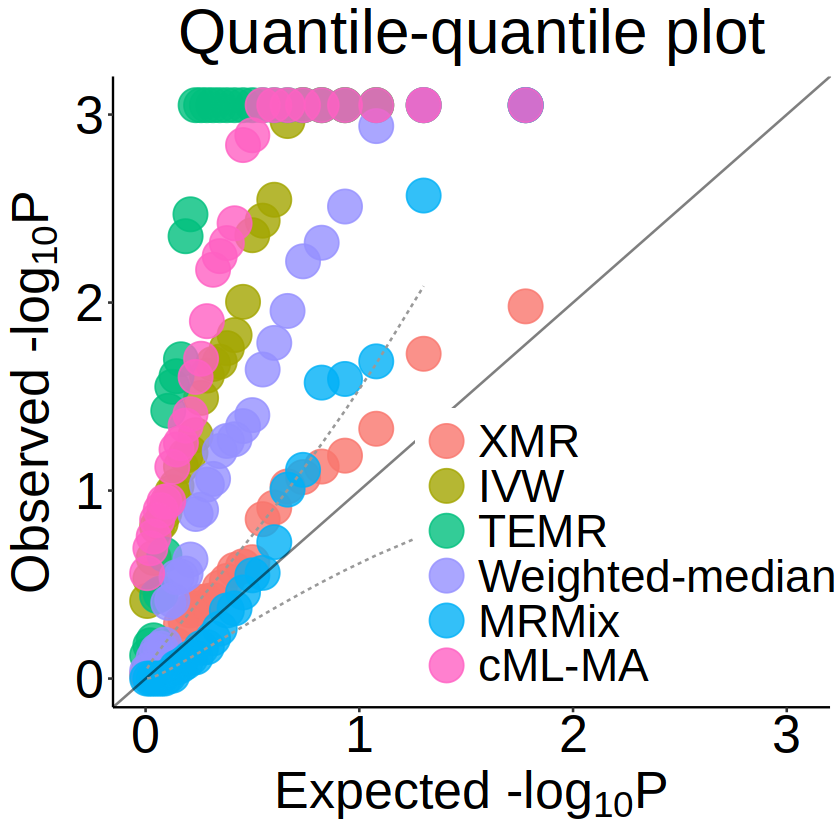

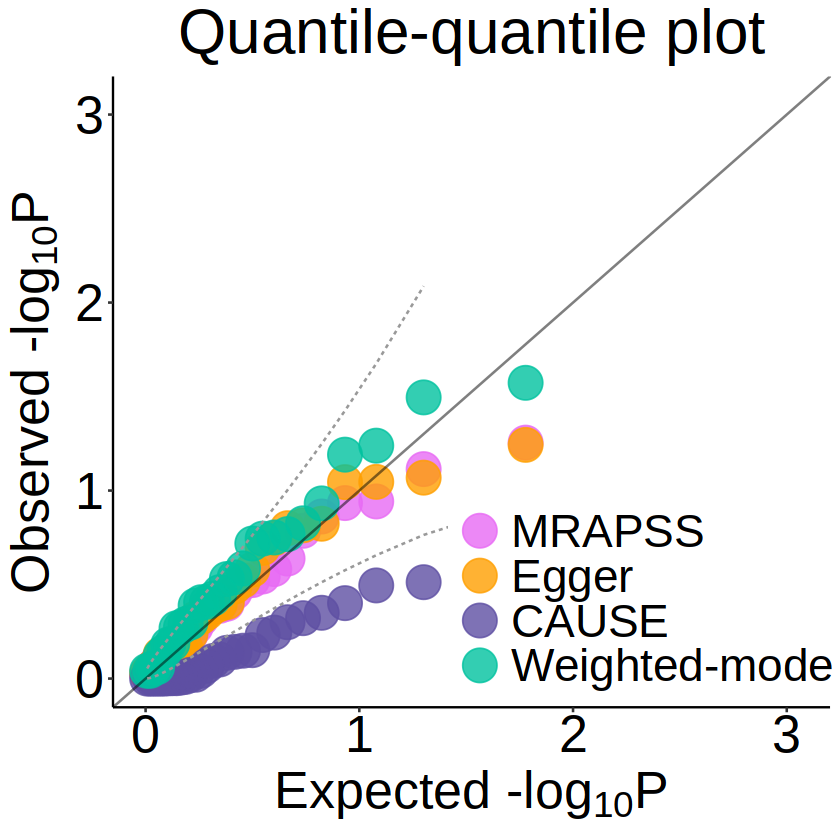

In [79]:
file_folder = paste0(base_dir, '/cor=',0,'_beta=0_t=5e-05/')
sim_null_plot(file_folder, cor = 0, lh=0.95, lw=0.8, max_num=3.05, size=9, use_color_map=TRUE, main_fig=TRUE, save=TRUE, 
              save_path1=paste0(base_dir, '/plots/null_cor=0-1.png'),
              save_path2=paste0(base_dir, '/plots/null_cor=0-2.png'),
              width=9.5, height=8.2, size_title = 37, size_aixs_title = 31, size_aixs_text = 31, size_legend_text = 27.2)

### Fig. S2

n= 30 
n= 27 


Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_line()`).”


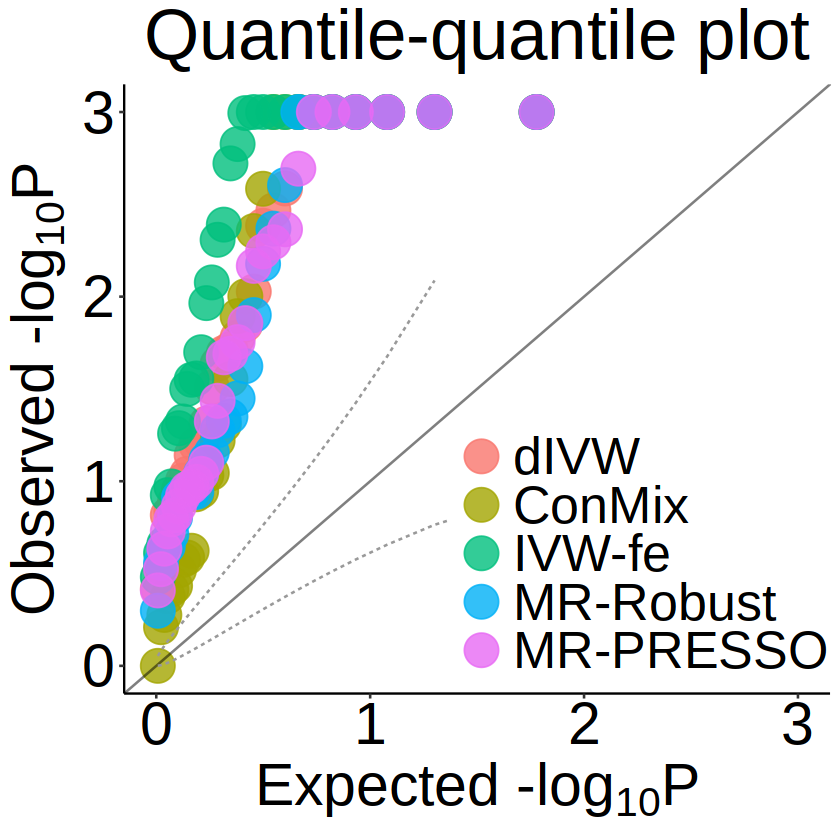

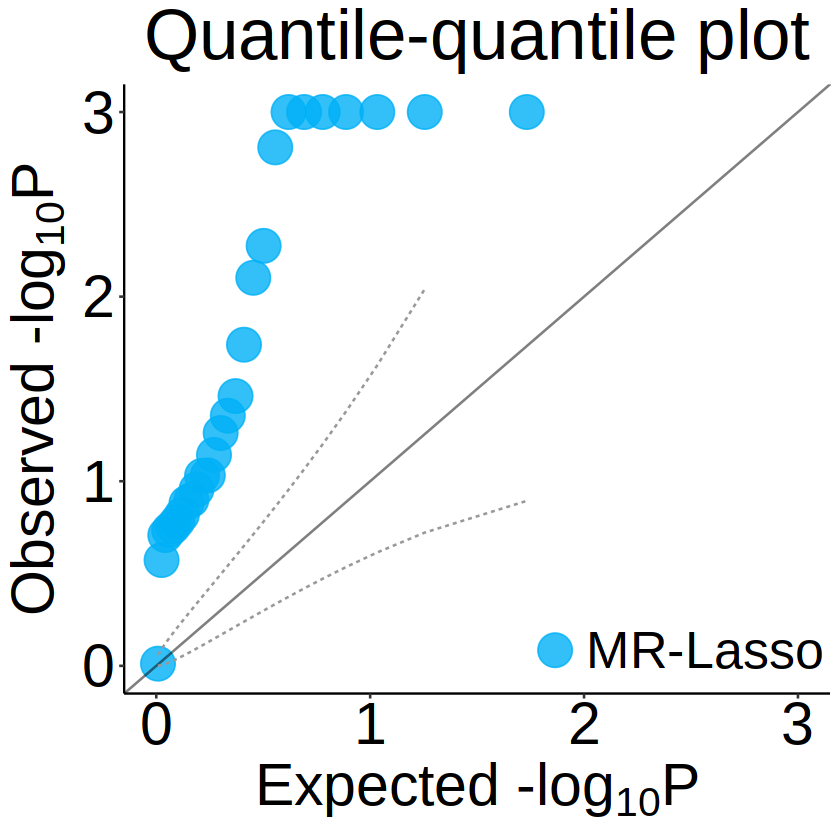

In [93]:
file_folder = paste0(base_dir, '/cor=',0,'_beta=0_t=5e-05/')
sim_null_plot(file_folder, cor = 0, lh=0.95, lw=0.8, max_num=3., size=9, use_color_map=FALSE, main_fig=FALSE, save=TRUE, 
              save_path1=paste0(base_dir, '/plots/null_cor=0-3.png'),
              save_path2=paste0(base_dir, '/plots/null_cor=0-4.png'),
              width=9., height=8., size_title = 42, size_aixs_title = 35, size_aixs_text = 35, size_legend_text = 31)

### cor = 0.3

#### Fig. 1B

n= 30 
n= 30 


Warning message:
“Removed 6 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range (`geom_line()`).”


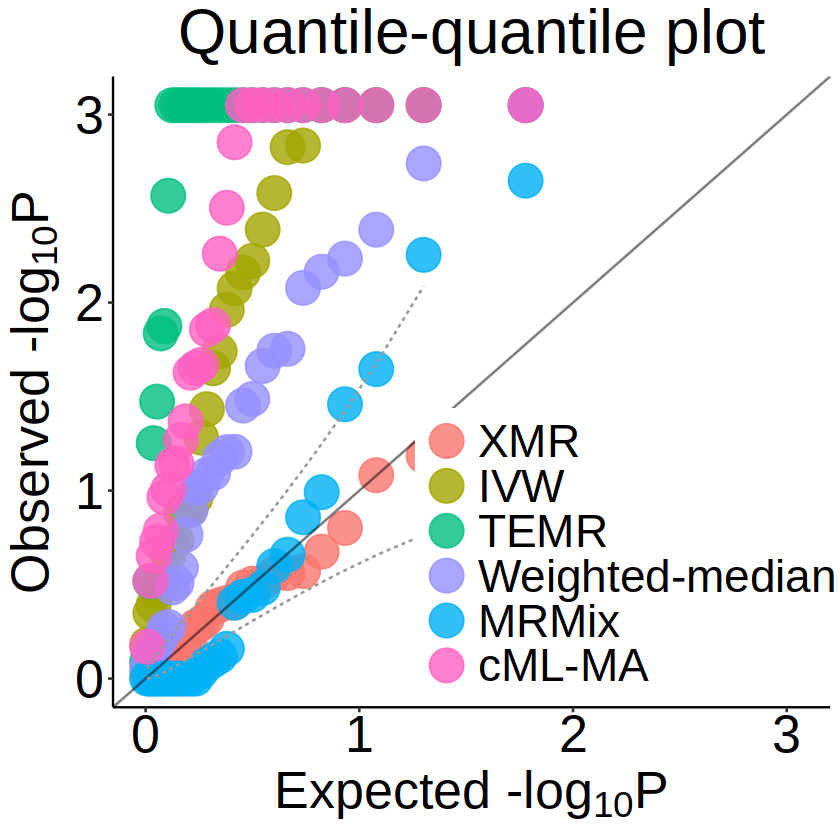

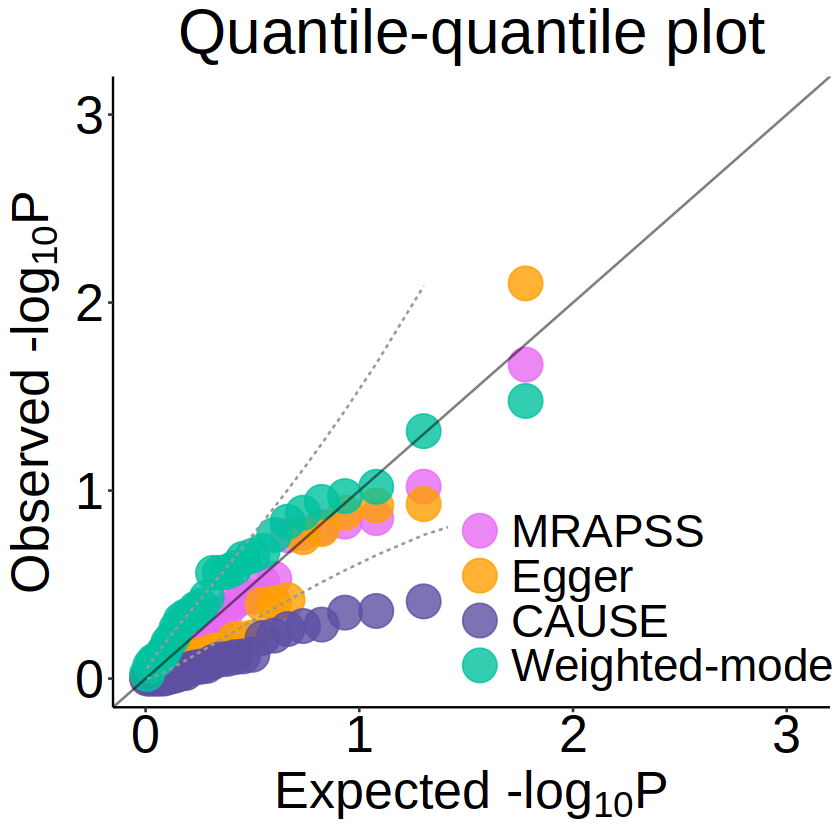

In [83]:
file_folder = paste0(base_dir, '/cor=',0.3,'_beta=0_t=5e-05/')
sim_null_plot(file_folder, cor = 0, lh=0.95, lw=0.8, max_num=3.05, size=9, use_color_map=TRUE, main_fig=TRUE, save=TRUE, 
              save_path1=paste0(base_dir, '/plots/null_cor=0.3-1.png'),
              save_path2=paste0(base_dir, '/plots/null_cor=0.3-2.png'),
              width=9.5, height=8.2, size_title = 37, size_aixs_title = 31, size_aixs_text = 31, size_legend_text = 27.2)

### Fig. S2

n= 30 
n= 28 


Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_line()`).”


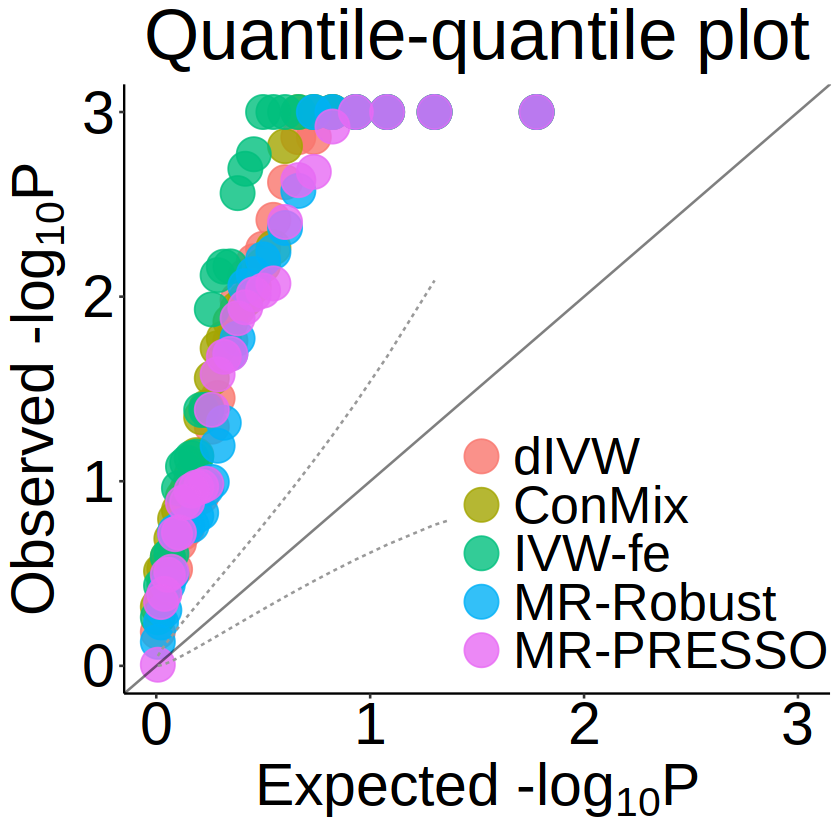

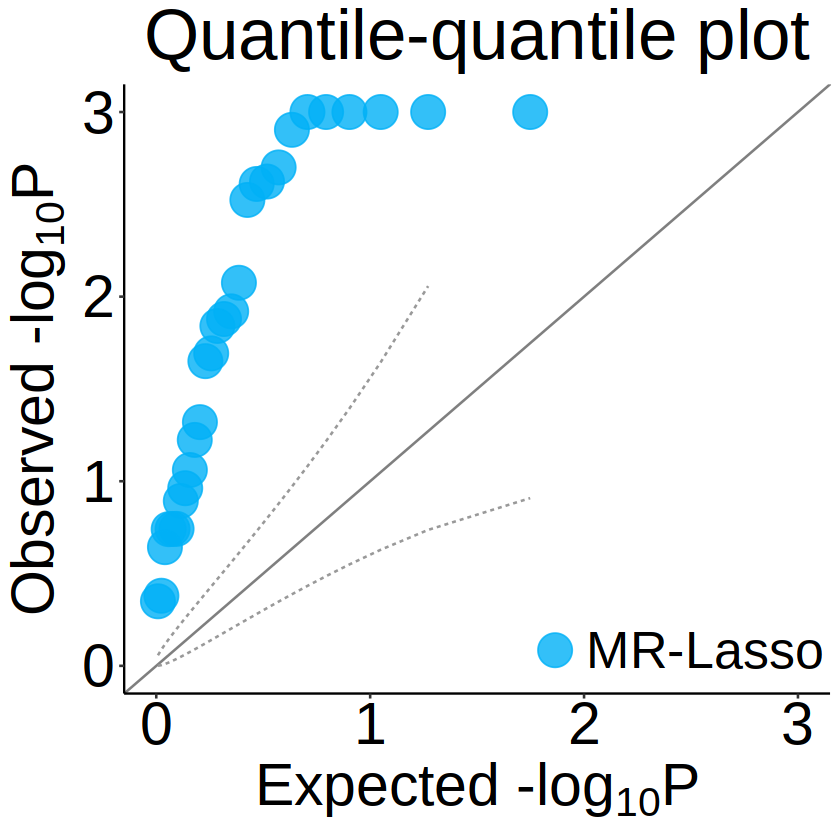

In [94]:
file_folder = paste0(base_dir, '/cor=',0.3,'_beta=0_t=5e-05/')
sim_null_plot(file_folder, cor = 0, lh=0.95, lw=0.8, max_num=3., size=9, use_color_map=FALSE, main_fig=FALSE, save=TRUE, 
              save_path1=paste0(base_dir, '/plots/null_cor=0.3-3.png'),
              save_path2=paste0(base_dir, '/plots/null_cor=0.3-4.png'),
              width=9., height=8., size_title = 42, size_aixs_title = 35, size_aixs_text = 35, size_legend_text = 31)

### cor = 0.7

#### Fig. 1C

n= 30 
n= 30 


Warning message:
“Removed 6 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range (`geom_line()`).”


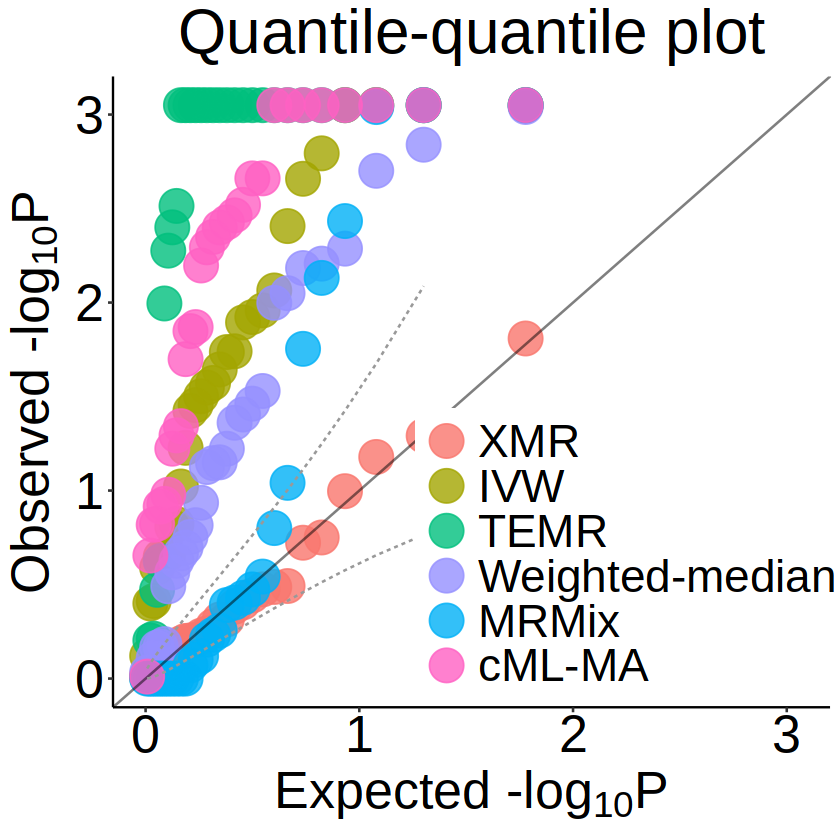

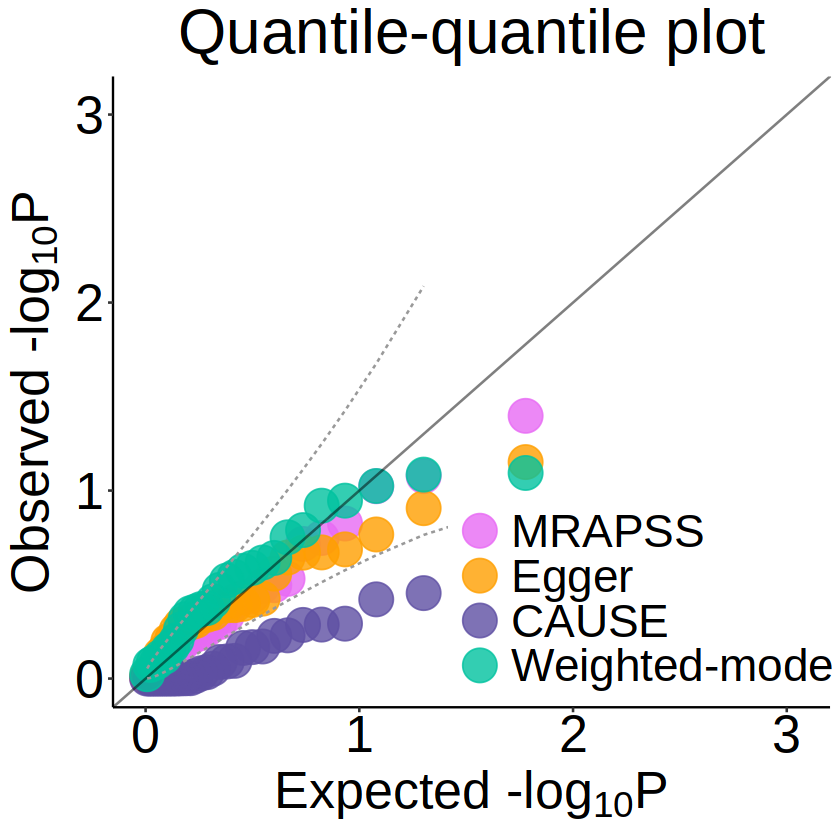

In [86]:
file_folder = paste0(base_dir, '/cor=',0.7,'_beta=0_t=5e-05/')
sim_null_plot(file_folder, cor = 0.7, lh=0.95, lw=0.8, max_num=3.05, size=9, use_color_map=TRUE, main_fig=TRUE, save=TRUE, 
              save_path1=paste0(base_dir, '/plots/null_cor=0.7-1.png'),
              save_path2=paste0(base_dir, '/plots/null_cor=0.7-2.png'),
              width=9.5, height=8.2, size_title = 37, size_aixs_title = 31, size_aixs_text = 31, size_legend_text = 27.2)

### Fig. S2

n= 30 
n= 30 


Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_line()`).”


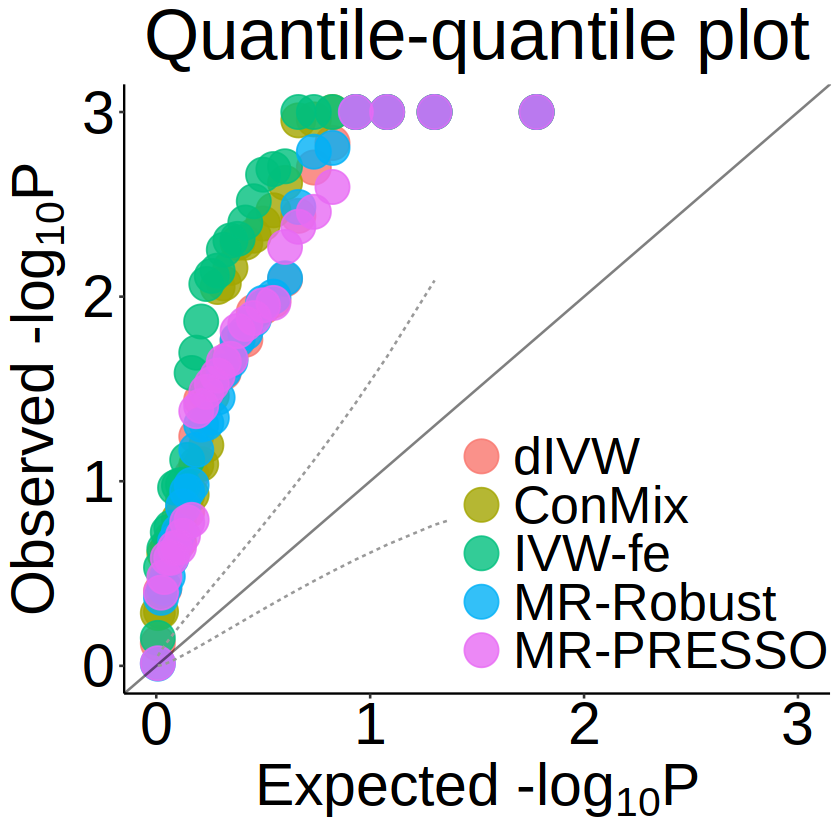

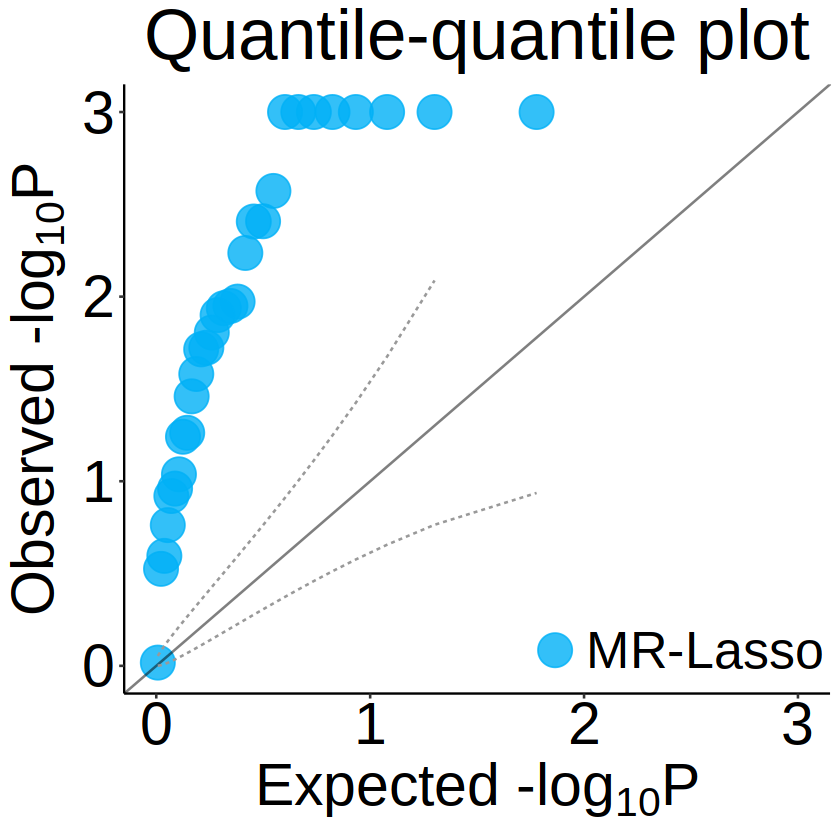

In [95]:
file_folder = paste0(base_dir, '/cor=',0.7,'_beta=0_t=5e-05/')
sim_null_plot(file_folder, cor = 0, lh=0.95, lw=0.8, max_num=3., size=9, use_color_map=FALSE, main_fig=FALSE, save=TRUE, 
              save_path1=paste0(base_dir, '/plots/null_cor=0.7-3.png'),
              save_path2=paste0(base_dir, '/plots/null_cor=0.7-4.png'),
              width=9., height=8., size_title = 42, size_aixs_title = 35, size_aixs_text = 35, size_legend_text = 31)

## Alternative cases

### cor = 0 (Fig. 1D)

In [112]:
pow_list = list()

cor = 0

for(beta in seq(0.05, 0.3, 0.05)){
    file_folder = paste0(base_dir, '/cor=',0,'_beta=',beta,'_t=5e-05/')
    pow_list = append(pow_list, list(sim_alt_plot(file_folder, true_beta = beta, plot = FALSE)))
}

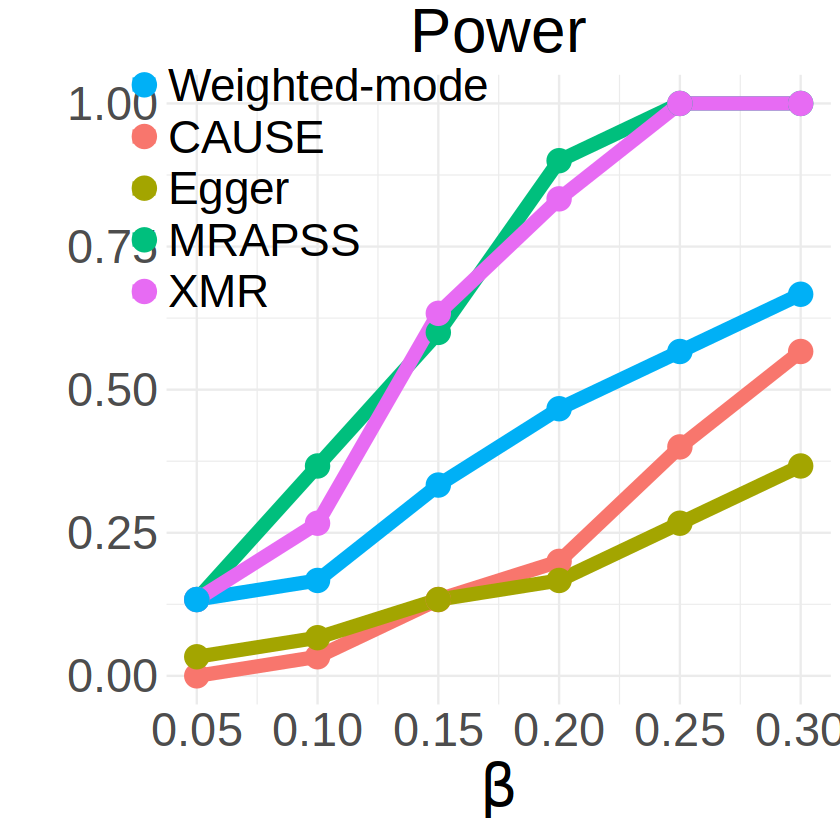

In [113]:
power_data = data.frame(rbindlist(pow_list),beta=c(rep(0.05,5), rep(0.1,5), 
                                                     rep(0.15,5), rep(0.2,5), 
                                                     rep(0.25,5), rep(0.3,5)))


power_data[power_data$method=='weighted mode','method'] = 'Weighted-mode'
power_data$method = factor(power_data$method, levels=c('Weighted-mode','CAUSE','Egger','MRAPSS','XMR'))

color_map <- c(
  "Weighted-mode" = "#00B0F6",  
  "CAUSE" = "#F8766D",         
  "Egger" = "#A3A500",        
  "MRAPSS" = "#00BF7D",        
  "XMR" = "#E76BF3"            
)

ggplot(power_data, aes(x = beta, y = power, color = method, group = method)) +
  geom_line(size = 3) +
  geom_point(size = 6.1) +
  labs(
    title = "Power",
    x = expression(beta),
  ) +
  ylab("") + 
  scale_x_continuous(breaks = unique(power_data$beta)) +  
  scale_color_manual(values = color_map) +
  theme_minimal() +
  theme(
    plot.title = element_text(                
      size = 37,
      hjust = 0.5,
      vjust = 1
    ),
    legend.position = c(0.22, 0.82),
    legend.text = element_text(size=27),
    legend.key.spacing.x = unit(1, 'cm'),
    legend.key.spacing.y = unit(0.2, 'cm'),
    legend.title = element_blank(),
    text = element_text(size = 35)
  ) +
  guides(fill = guide_legend(byrow = TRUE))

ggsave(paste0(base_dir, '/plots/power_cor=0.png'), width = 9.5, height = 8, bg = "white")

### cor = 0.3 (Fig. 1E)

In [109]:
pow_list = list()

cor = 0.3

for(beta in seq(0.05, 0.3, 0.05)){
    file_folder = paste0(base_dir, '/cor=',0.3,'_beta=',beta,'_t=5e-05/')
    pow_list = append(pow_list, list(sim_alt_plot(file_folder, true_beta = beta, plot = FALSE)))
}

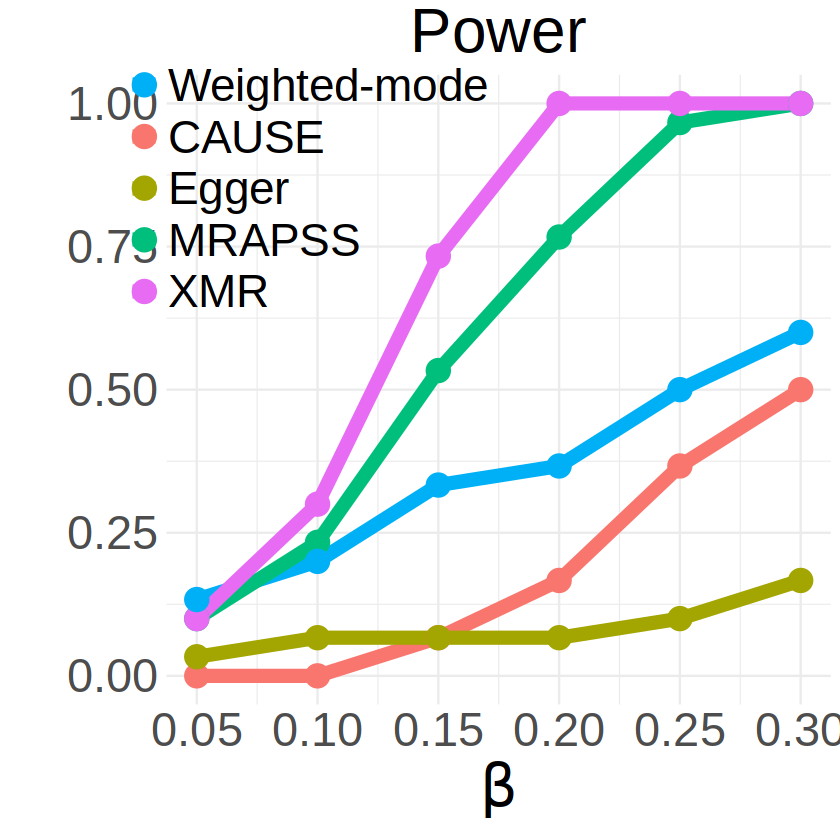

In [111]:
power_data = data.frame(rbindlist(pow_list),beta=c(rep(0.05,5), rep(0.1,5), 
                                                     rep(0.15,5), rep(0.2,5), 
                                                     rep(0.25,5), rep(0.3,5)))


power_data[power_data$method=='weighted mode','method'] = 'Weighted-mode'
power_data$method = factor(power_data$method, levels=c('Weighted-mode','CAUSE','Egger','MRAPSS','XMR'))

color_map <- c(
  "Weighted-mode" = "#00B0F6",  
  "CAUSE" = "#F8766D",         
  "Egger" = "#A3A500",        
  "MRAPSS" = "#00BF7D",        
  "XMR" = "#E76BF3"            
)

ggplot(power_data, aes(x = beta, y = power, color = method, group = method)) +
  geom_line(size = 3) +
  geom_point(size = 6.1) +
  labs(
    title = "Power",
    x = expression(beta),
  ) +
  ylab("") + 
  scale_x_continuous(breaks = unique(power_data$beta)) +  
  scale_color_manual(values = color_map) +
  theme_minimal() +
  theme(
    plot.title = element_text(                
      size = 37,
      hjust = 0.5,
      vjust = 1
    ),
    legend.position = c(0.22, 0.82),
    legend.text = element_text(size=27),
    legend.key.spacing.x = unit(1, 'cm'),
    legend.key.spacing.y = unit(0.2, 'cm'),
    legend.title = element_blank(),
    text = element_text(size = 35)
  ) +
  guides(fill = guide_legend(byrow = TRUE))

ggsave(paste0(base_dir, '/plots/power_cor=0.3.png'), width = 9.5, height = 8, bg = "white")

### cor = 0.7 (Fig. 1F)

In [100]:
pow_list = list()

cor = 0.7

for(beta in seq(0.05, 0.3, 0.05)){
    file_folder = paste0(base_dir, '/cor=',0.7,'_beta=',beta,'_t=5e-05/')
    pow_list = append(pow_list, list(sim_alt_plot(file_folder, true_beta = beta, plot = FALSE)))
}

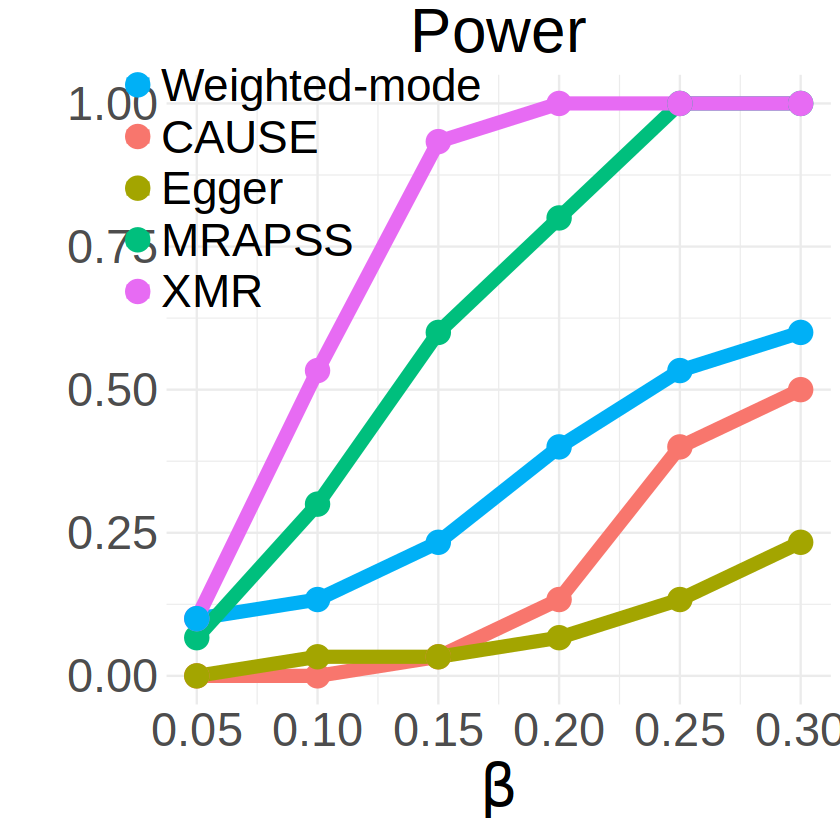

In [108]:
power_data = data.frame(rbindlist(pow_list),beta=c(rep(0.05,5), rep(0.1,5), 
                                                     rep(0.15,5), rep(0.2,5), 
                                                     rep(0.25,5), rep(0.3,5)))


power_data[power_data$method=='weighted mode','method'] = 'Weighted-mode'
power_data$method = factor(power_data$method, levels=c('Weighted-mode','CAUSE','Egger','MRAPSS','XMR'))

color_map <- c(
  "Weighted-mode" = "#00B0F6",  
  "CAUSE" = "#F8766D",         
  "Egger" = "#A3A500",        
  "MRAPSS" = "#00BF7D",        
  "XMR" = "#E76BF3"            
)

ggplot(power_data, aes(x = beta, y = power, color = method, group = method)) +
  geom_line(size = 3) +
  geom_point(size = 6.1) +
  labs(
    title = "Power",
    x = expression(beta),
  ) +
  ylab("") + 
  scale_x_continuous(breaks = unique(power_data$beta)) +  
  scale_color_manual(values = color_map) +
  theme_minimal() +
  theme(
    plot.title = element_text(                
      size = 37,
      hjust = 0.5,
      vjust = 1
    ),
    legend.position = c(0.21, 0.82),
    legend.text = element_text(size=27),
    legend.key.spacing.x = unit(1, 'cm'),
    legend.key.spacing.y = unit(0.2, 'cm'),
    legend.title = element_blank(),
    text = element_text(size = 35)
  ) +
  guides(fill = guide_legend(byrow = TRUE))

ggsave(paste0(base_dir, '/plots/power_cor=0.7.png'), width = 9.5, height = 8, bg = "white")

### Figs. 1I, S4-S6

[1] "cor=0"


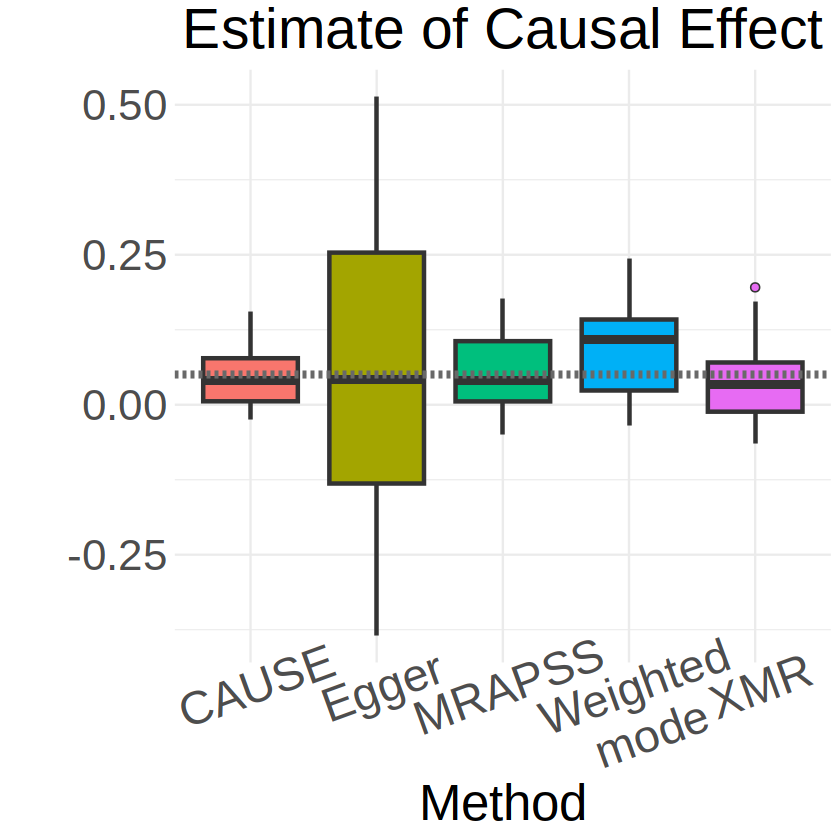

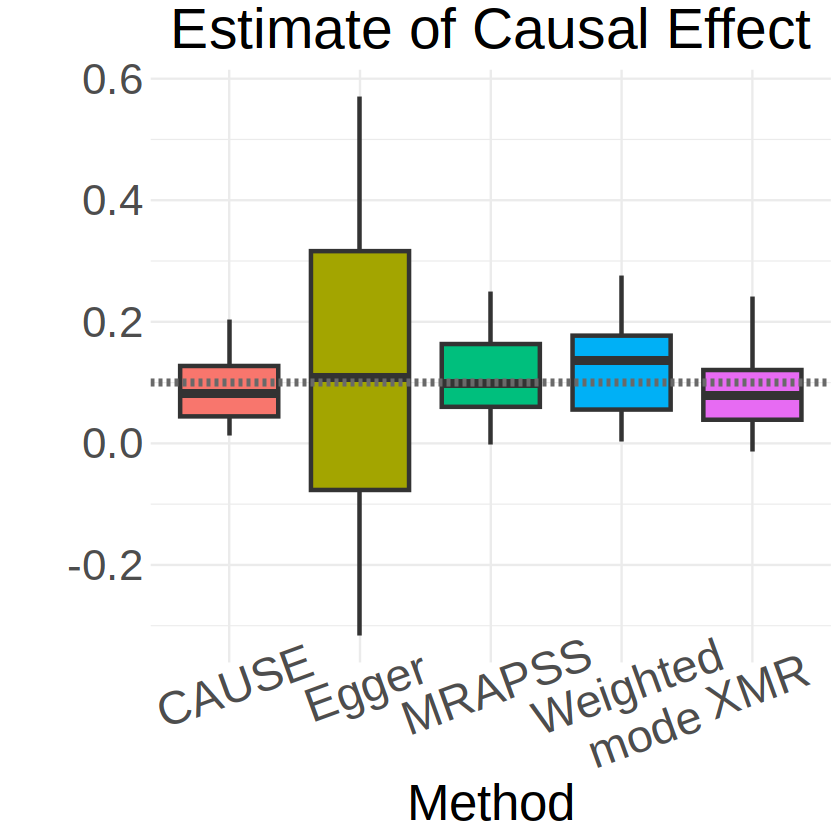

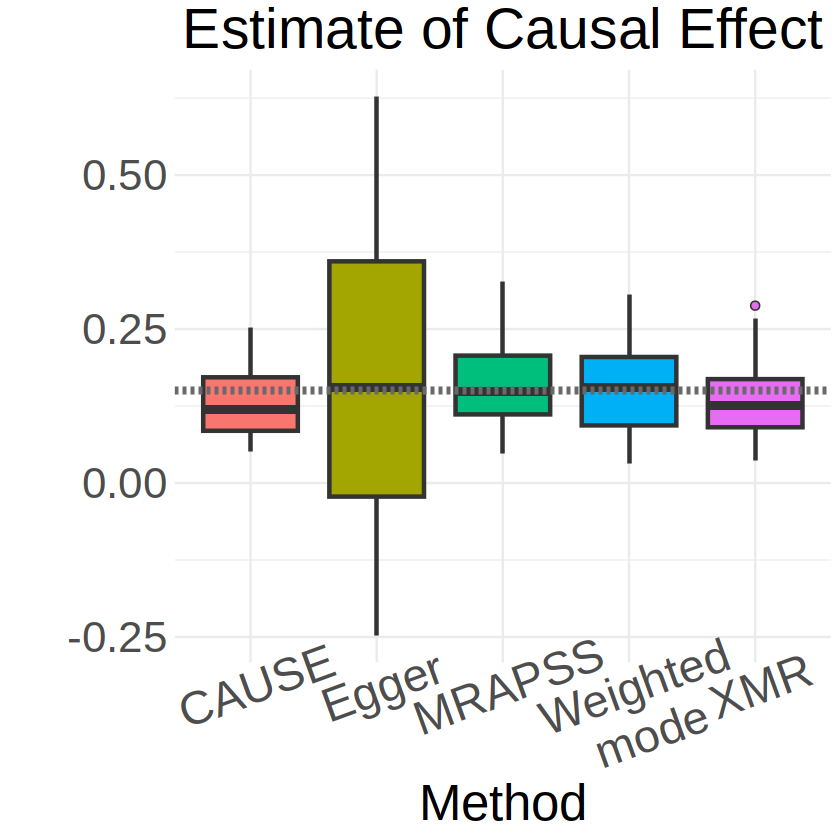

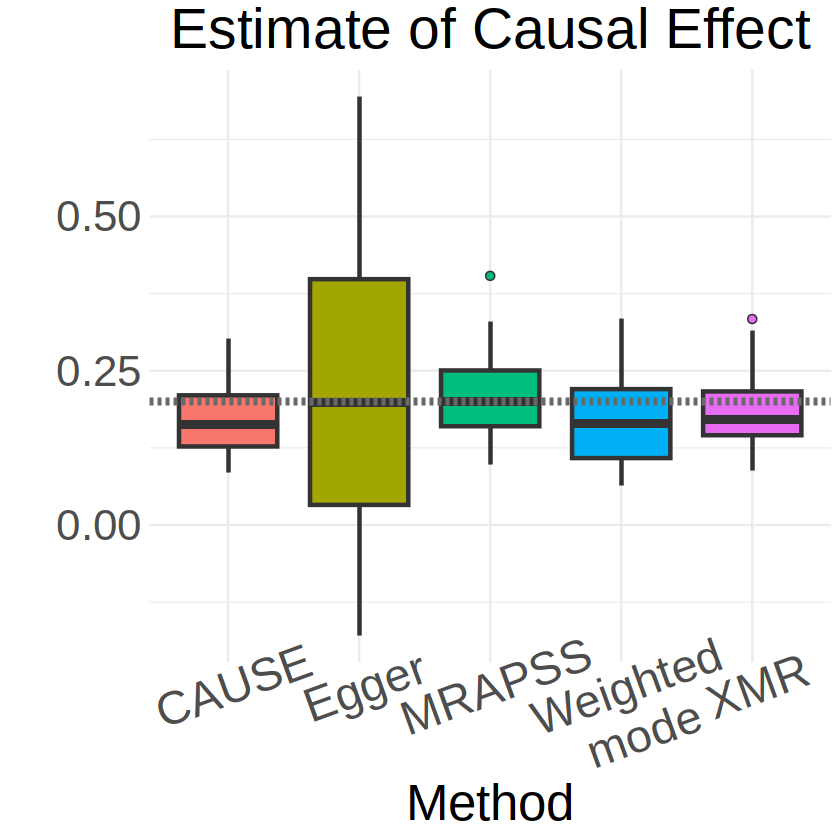

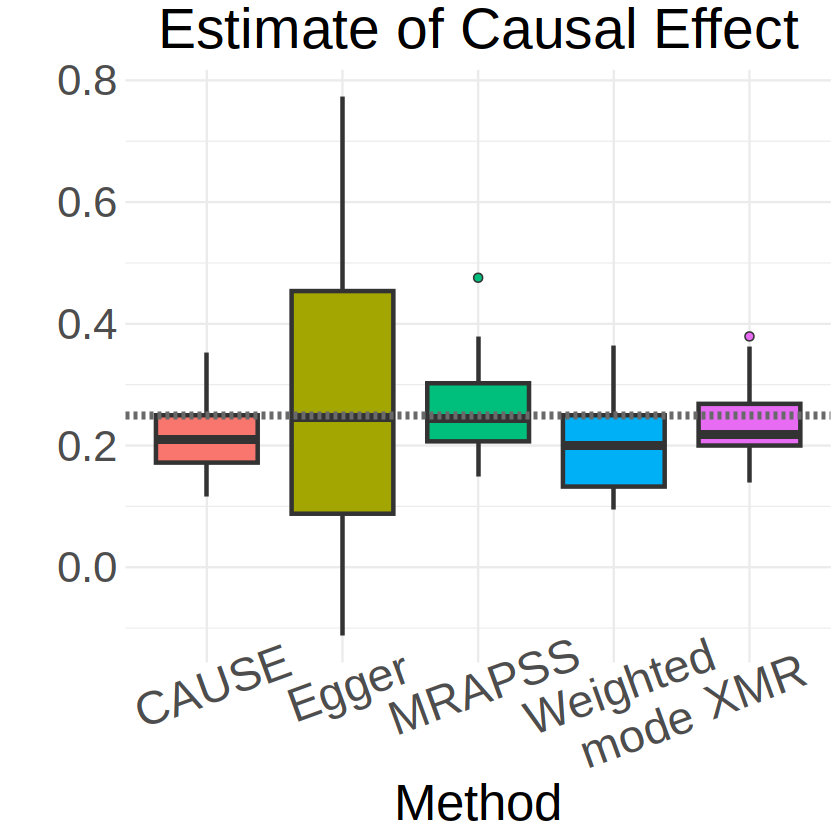

[1] "cor=0.3"


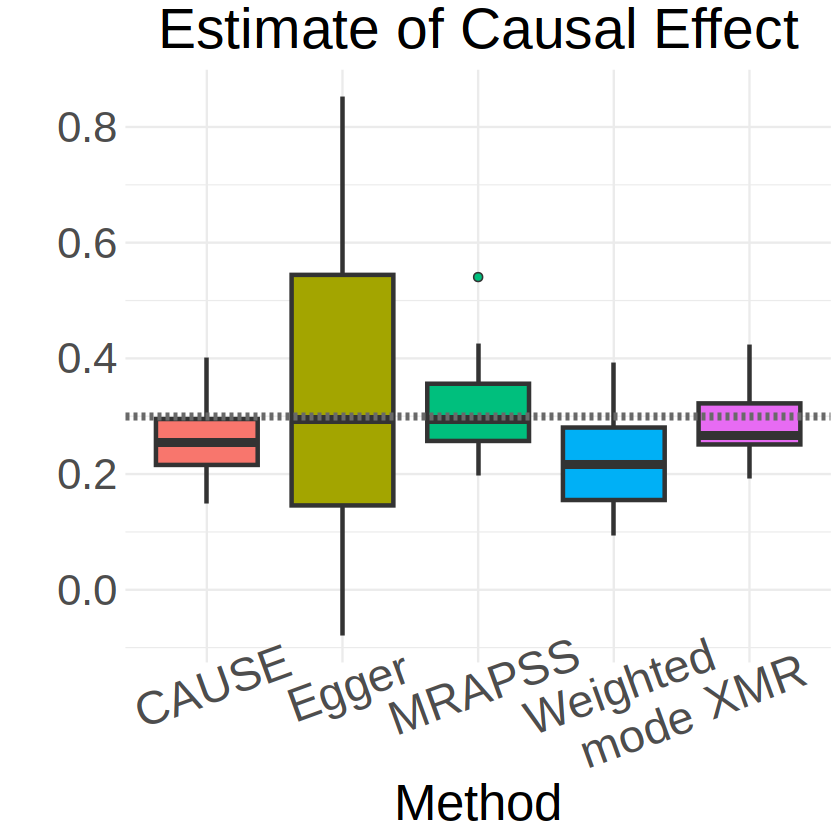

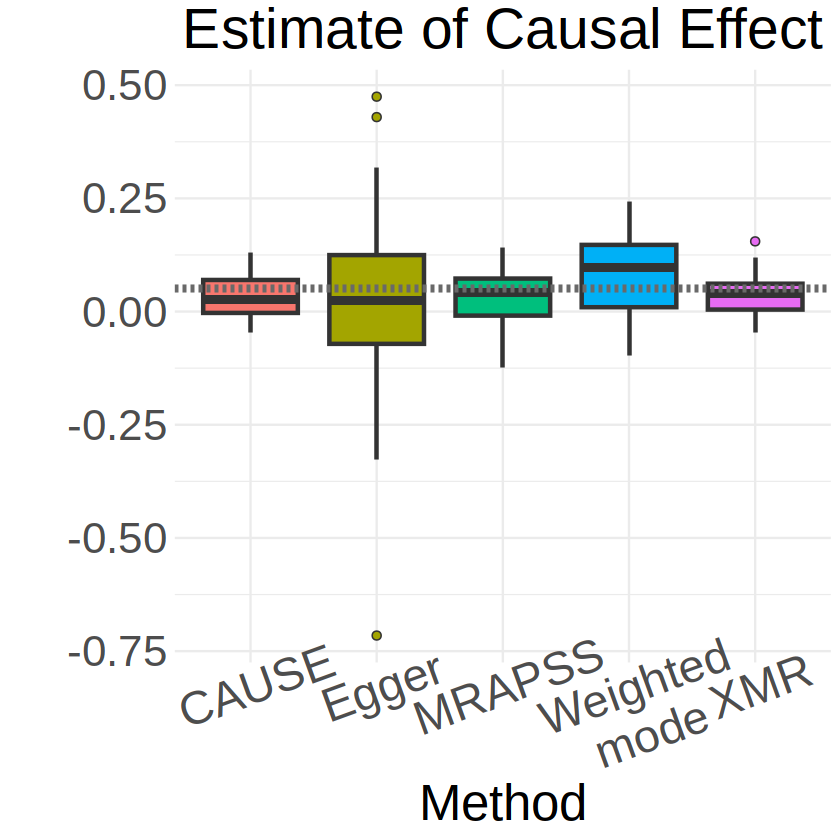

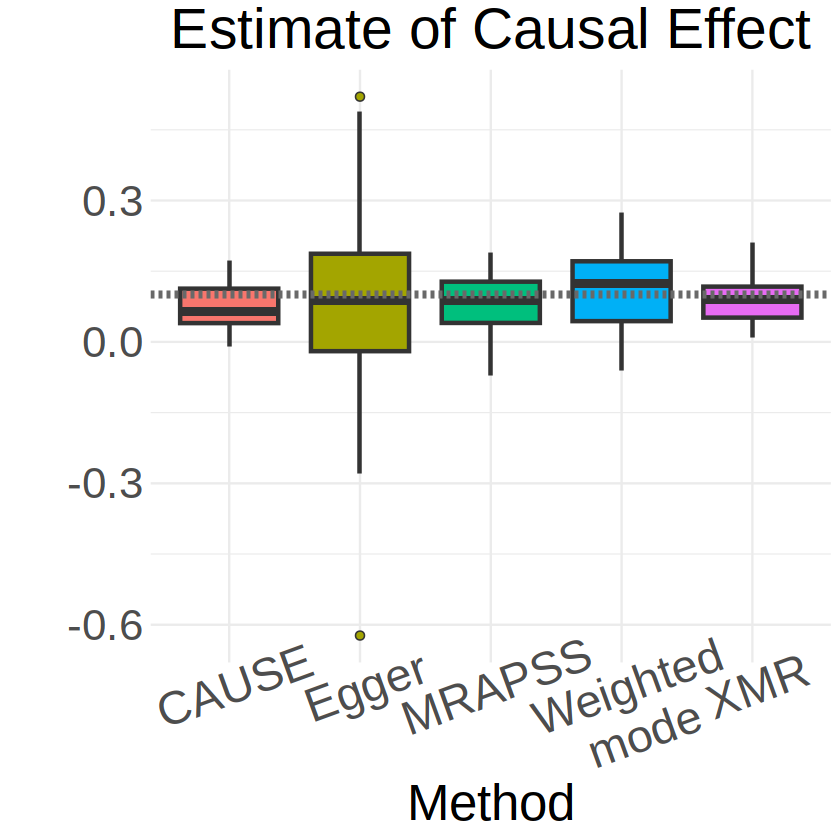

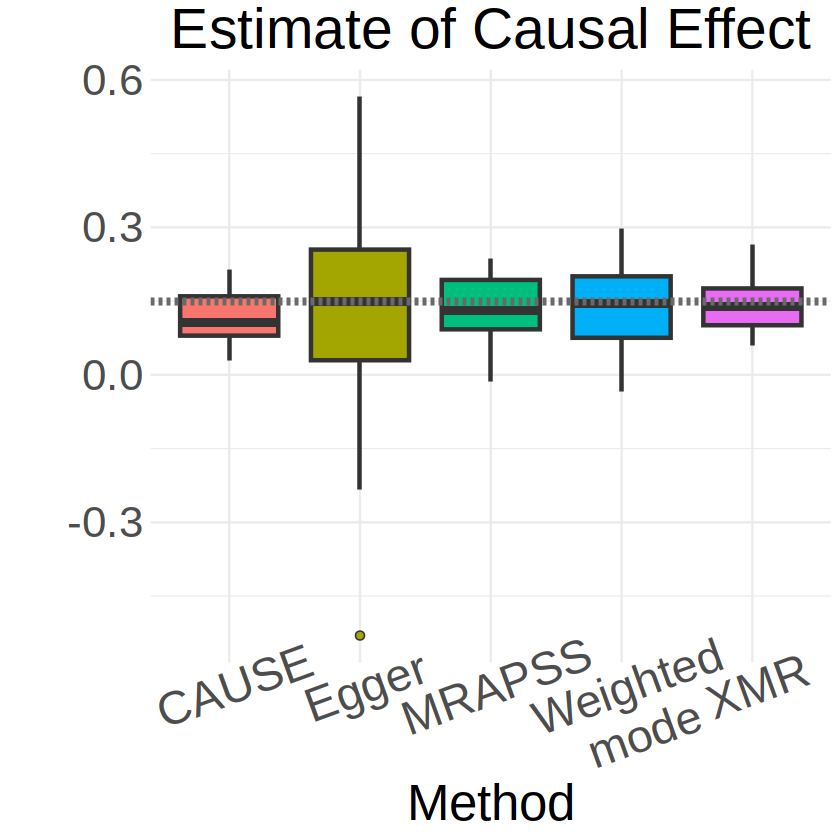

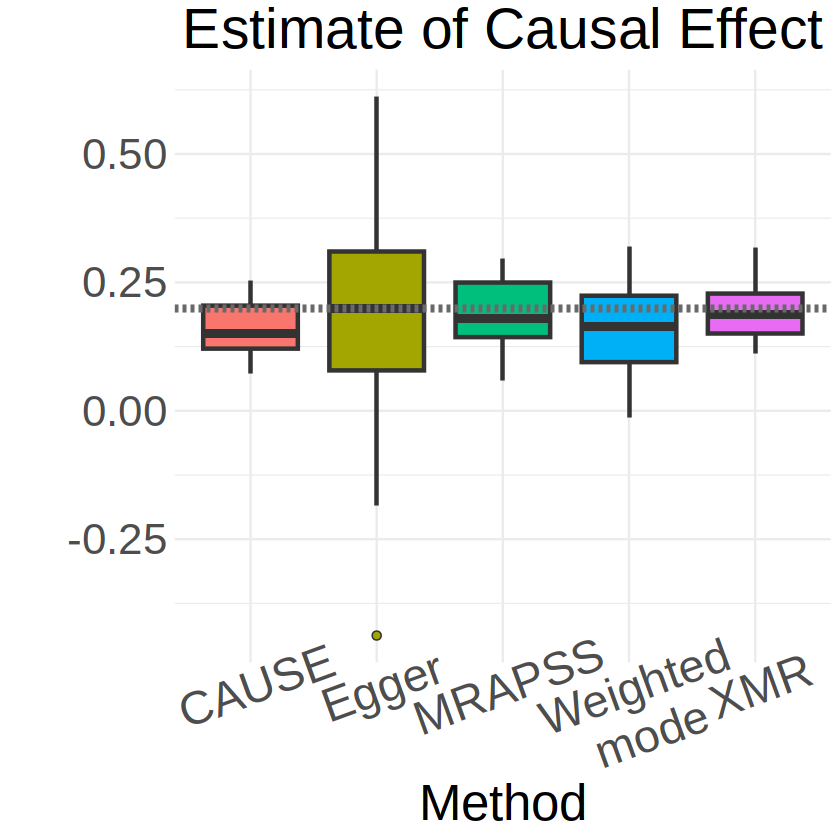

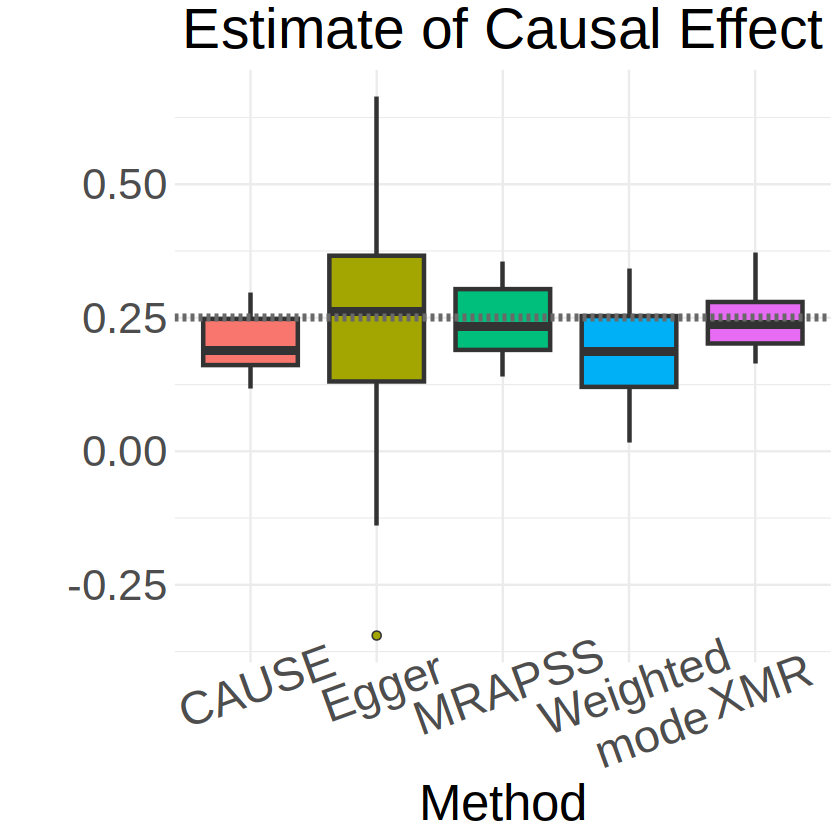

[1] "cor=0.7"


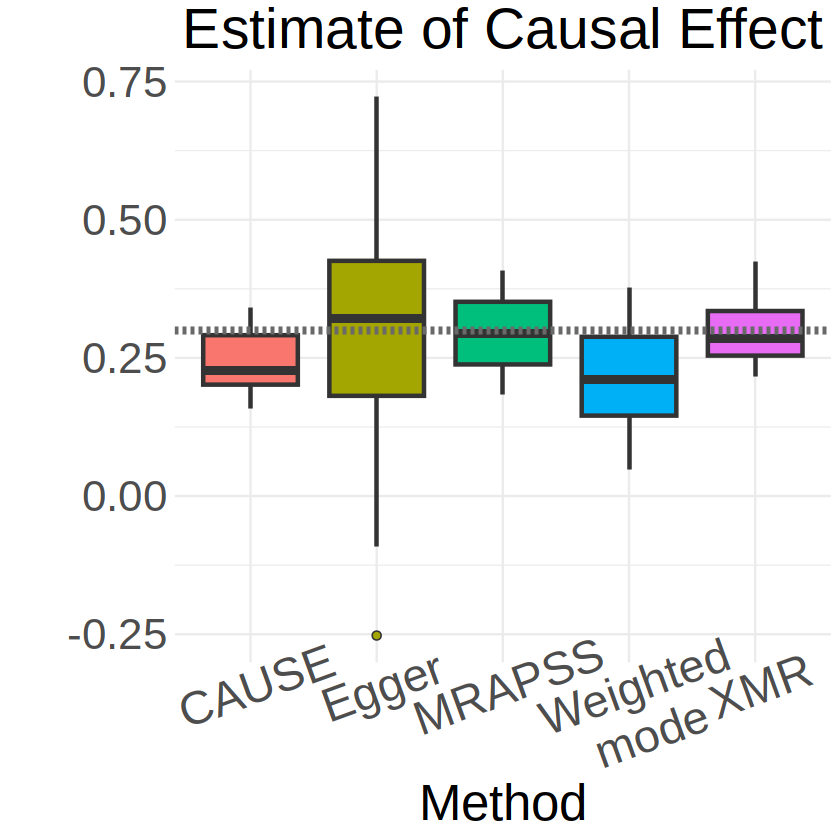

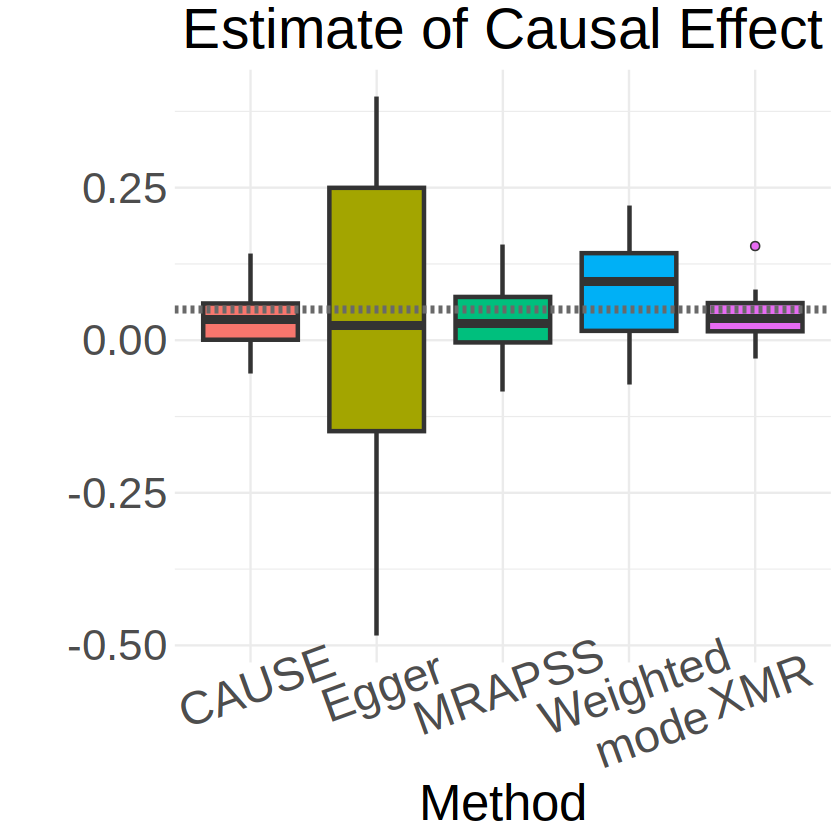

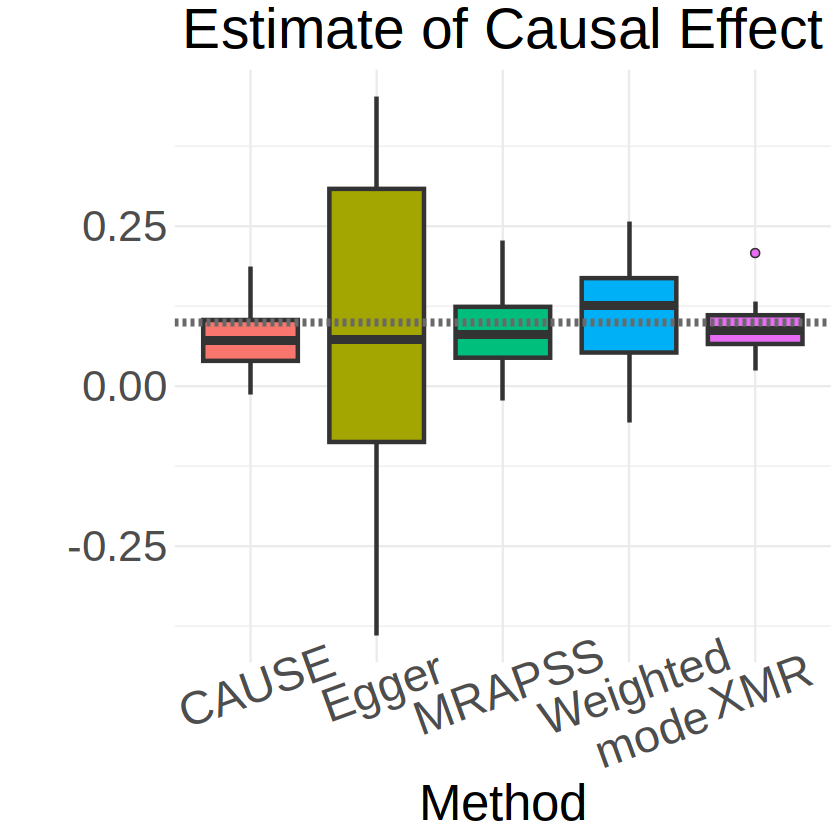

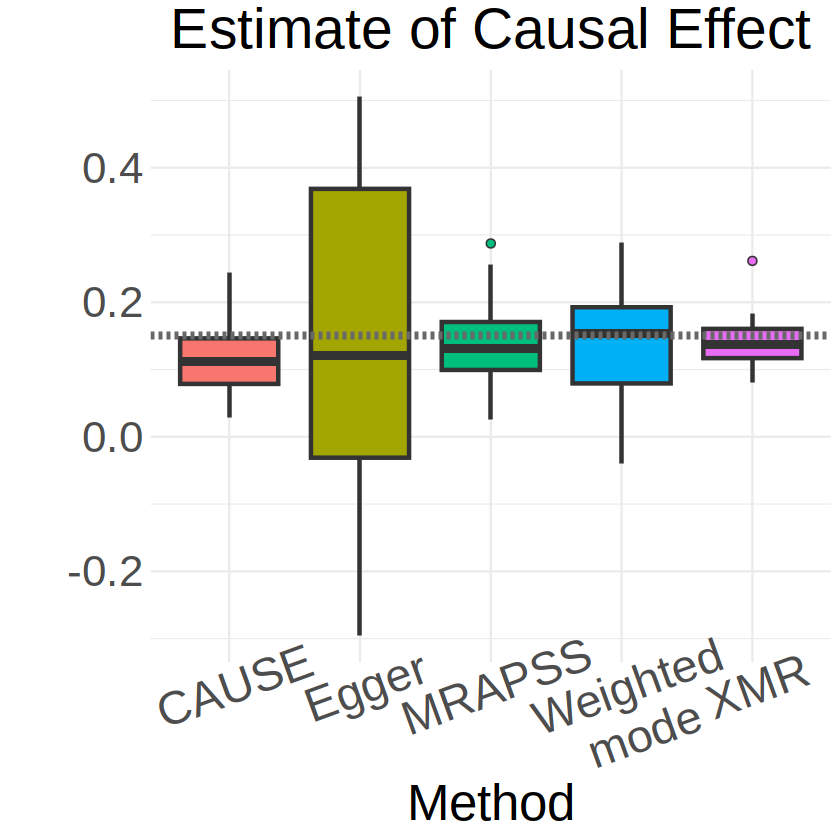

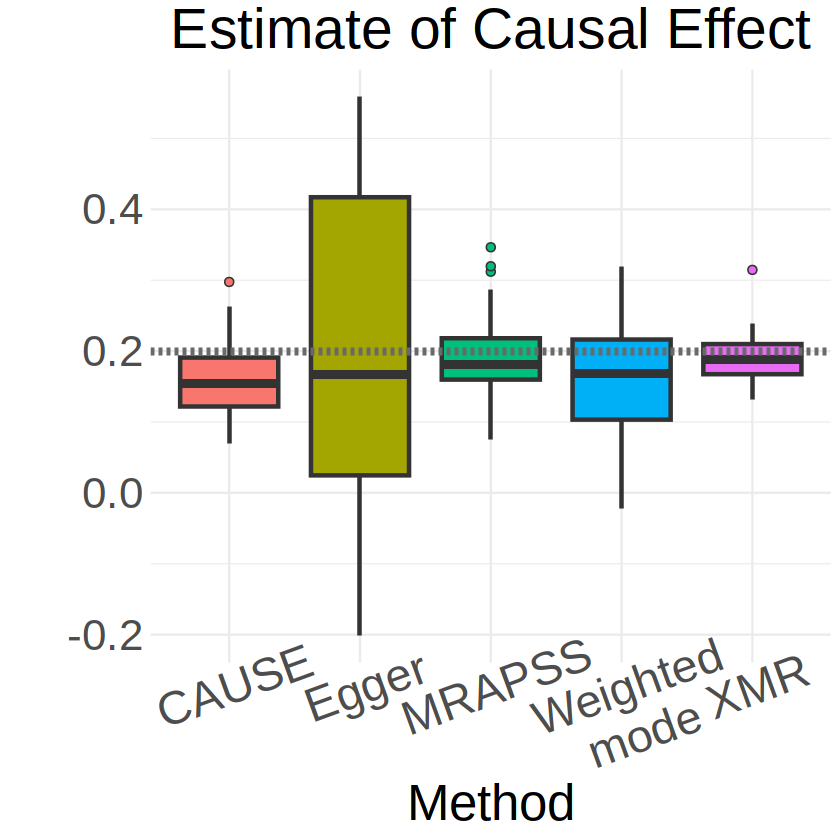

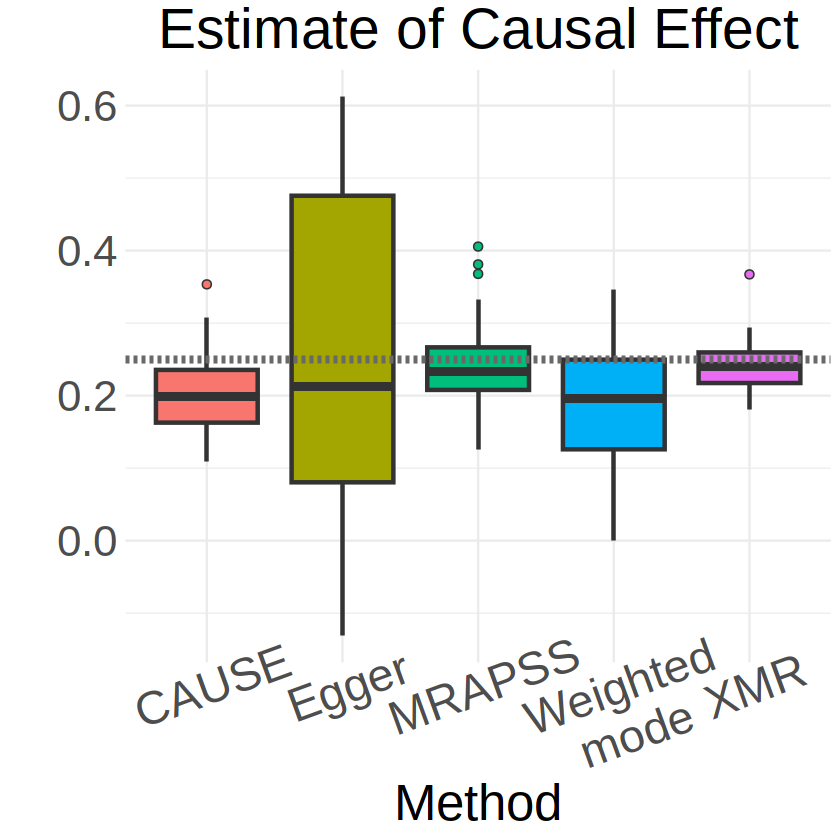

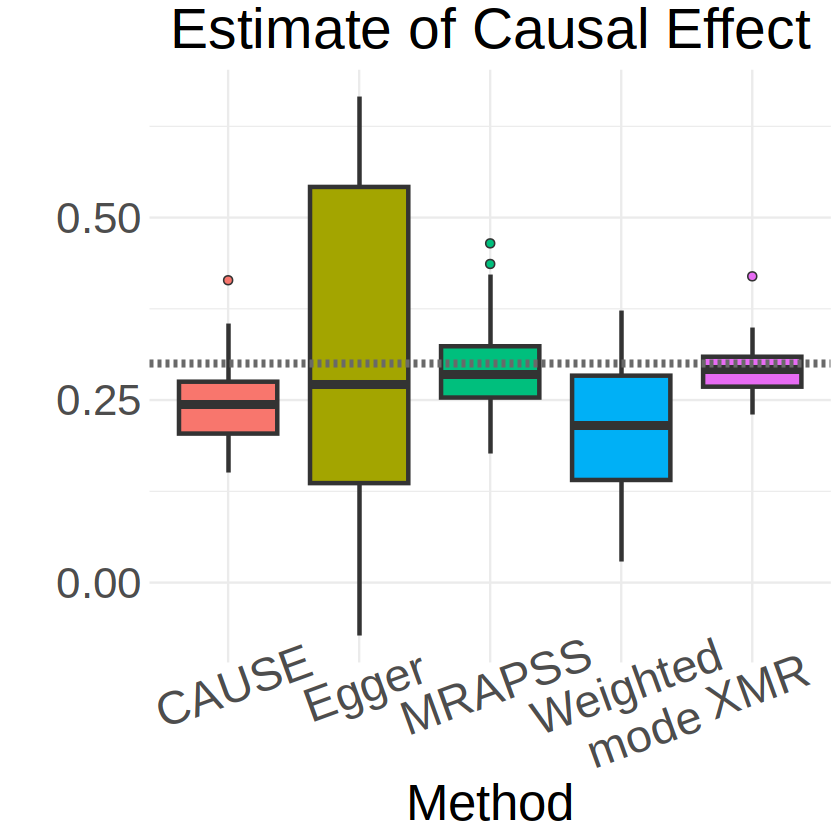

In [117]:
for(cor in c(0., 0.3, 0.7)){
    print(paste0('cor=',cor))
    for(beta in seq(0.05, 0.3, 0.05)){
        file_folder = paste0(base_dir, '/cor=',cor,'_beta=',beta,'_t=5e-05/')
        sim_alt_plot(file_folder, true_beta = beta, plot = TRUE)
        ggsave(paste0(file_folder, '/beta_estimate.png'), width = 9, height = 8)
    }
}

### Fig. 1G

In [121]:
df_xmr_5 = fread(paste0(base_dir, '/cor=0.3_beta=0.2_t=5e-05/XMR.MRres'))
df_xmr_6 = fread(paste0(base_dir, '/cor=0.3_beta=0.2_t=5e-06/XMR.MRres'))
df_xmr_7 = fread(paste0(base_dir, '/cor=0.3_beta=0.2_t=5e-07/XMR.MRres'))

df_mrapss_5 = fread(paste0(base_dir, '/cor=0.3_beta=0.2_t=5e-05/MRAPSS.MRres'))
df_mrapss_6 = fread(paste0(base_dir, '/cor=0.3_beta=0.2_t=5e-06/MRAPSS.MRres'))
df_mrapss_7 = fread(paste0(base_dir, '/cor=0.3_beta=0.2_t=5e-07/MRAPSS.MRres'))

colnames(df_xmr_5) = c("beta","beta.se","beta.pvalue","tau.sq","sigmax11","sigmax12","sigmax22","nIV","IVsignal.sum",
                       "nvalid","pi0","Threshold0","Threshold","exp_N1","exp_N2","faket")
colnames(df_xmr_6) = colnames(df_xmr_5)
colnames(df_xmr_7) = colnames(df_xmr_5)

colnames(df_mrapss_5) = c("beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold")
colnames(df_mrapss_6) = colnames(df_mrapss_5)
colnames(df_mrapss_7) = colnames(df_mrapss_5)

df_xmr = rbind(rbind(df_xmr_5, df_xmr_6), df_xmr_7)
df_xmr$n_invalid = df_xmr$nIV - df_xmr$nvalid

df_mrapss = rbind(rbind(df_mrapss_5, df_mrapss_6), df_mrapss_7)
df_mrapss$nvalid = df_mrapss$nIV*df_mrapss$pi0
df_mrapss$n_invalid = df_mrapss$nIV - df_mrapss$nvalid

df_all = data.frame(rbind(df_xmr[,c('nvalid','n_invalid')],df_mrapss[,c('nvalid','n_invalid')]), 
                    method=rep(c('XMR','MRAPSS'), each=90), threshold = c(df_xmr$Threshold0, df_mrapss$Threshold))


library(tidyr)

df_mean <- df_all %>%
  group_by(threshold, method) %>%
  summarize(
    nvalid = mean(nvalid, na.rm = TRUE),
    n_invalid = mean(n_invalid, na.rm = TRUE)
  ) %>%
  pivot_longer(
    cols = c(nvalid, n_invalid),
    names_to = "type",
    values_to = "value"
  ) %>%
  mutate(
    fill_color = case_when(
      method == "XMR" & type == "nvalid" ~ "XMR Valid",
      method == "XMR" & type == "n_invalid" ~ "XMR Invalid",
      method == "MRAPSS" & type == "nvalid" ~ "MRAPSS Valid",
      method == "MRAPSS" & type == "n_invalid" ~ "MRAPSS Invalid"
    )
  )

`summarise()` has grouped output by 'threshold'. You can override using the `.groups` argument.


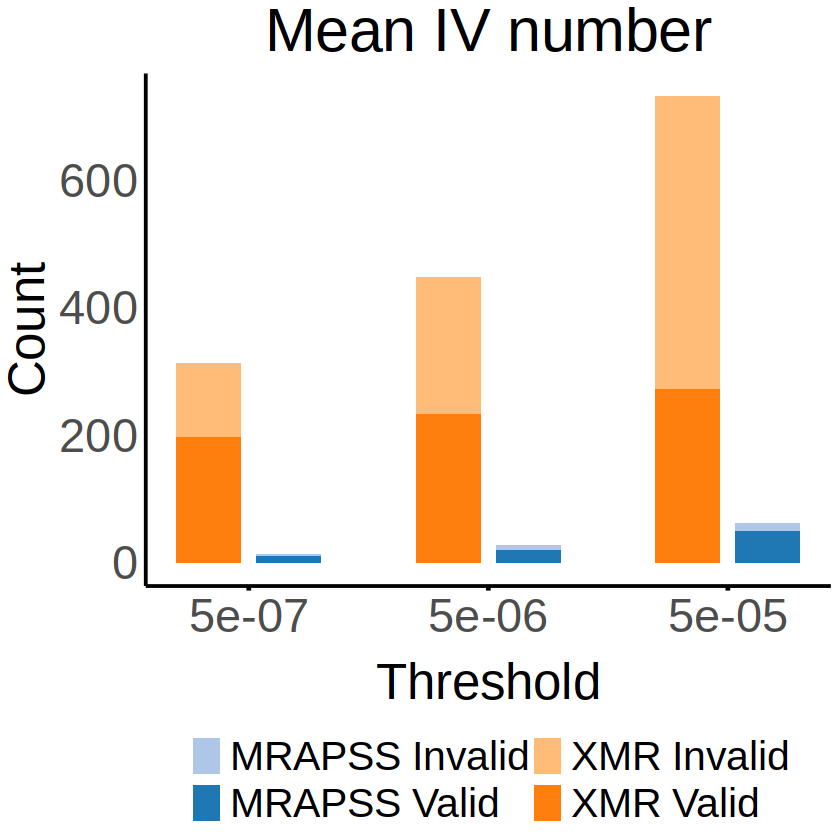

In [123]:
color_map <- c(
  "XMR.nvalid" = "#ff7f0e",    
  "XMR.n_invalid" = "#ffbb78", 
  "MRAPSS.nvalid" = "#1f77b4",       
  "MRAPSS.n_invalid" = "#aec7e8" 
)

df_mean <- df_mean %>%
  mutate(
    fill_color = factor(fill_color, levels = c(
      "XMR.n_invalid", "MRAPSS.n_invalid",   
      "XMR.nvalid", "MRAPSS.nvalid"
    ))
  )

df_mean <- df_mean %>%
  mutate(
    x = case_when(
      threshold == "5e-07" & method == "XMR" ~ 1,  
      threshold == "5e-07" & method == "MRAPSS" ~ 2,
      threshold == "5e-06" & method == "XMR" ~ 4,  
      threshold == "5e-06" & method == "MRAPSS" ~ 5,
      threshold == "5e-05" & method == "XMR" ~ 7,  
      threshold == "5e-05" & method == "MRAPSS" ~ 8
    )
  )

x_labels <- c("5e-07", "5e-06", "5e-05")
x_positions <- c(1.5, 4.5, 7.5)

legend_labels <- c(
  "XMR.nvalid" = "XMR Valid",
  "XMR.n_invalid" = "XMR Invalid",
  "MRAPSS.nvalid" = "MRAPSS Valid",
  "MRAPSS.n_invalid" = "MRAPSS Invalid"
)

main_plot = ggplot(df_mean, aes(x = x, y = value, fill = interaction(method,type))) +
  geom_bar(stat = "identity", position = "stack", width = 0.8) +
  scale_fill_manual(values = color_map, labels = legend_labels) +
  labs(
    x = "Threshold",
    y = "Count",
    title = "Mean IV number"
  ) +
  scale_x_continuous(
    breaks = x_positions,  
    labels = x_labels      
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(size = 36, hjust = 0.5),
    panel.grid = element_blank(),           
    axis.line.x = element_line(size = 0.8, color = "black"),  # 启用x轴线
    axis.line.y = element_line(size = 0.8, color = "black"),
    axis.text.x = element_text(size = 28),  
    axis.text.y = element_text(size = 28),  
    axis.title.x = element_text(size = 30, margin = margin(t = 13)),  
    axis.title.y = element_text(size = 30),  
    axis.ticks.x = element_line(size = 1), 
    legend.title = element_blank(),
    legend.text = element_text(size = 24),
    legend.position = "bottom",
    #legend.key.width = unit(2, "cm"),
    #legend.key.height = unit(1, "cm"),
    legend.spacing.x = unit(10, "cm"),
    legend.spacing.y = unit(5, "cm")
  ) +
  guides(
    fill = guide_legend(
      #override.aes = list(size = 5),  
      nrow = 2, byrow = TRUE,
      title.position = "top"          
    )
  )

main_plot
ggsave(paste0(base_dir, '/plots/num_IV.png'), width = 9, height = 8, bg='white')

### Fig. 1H

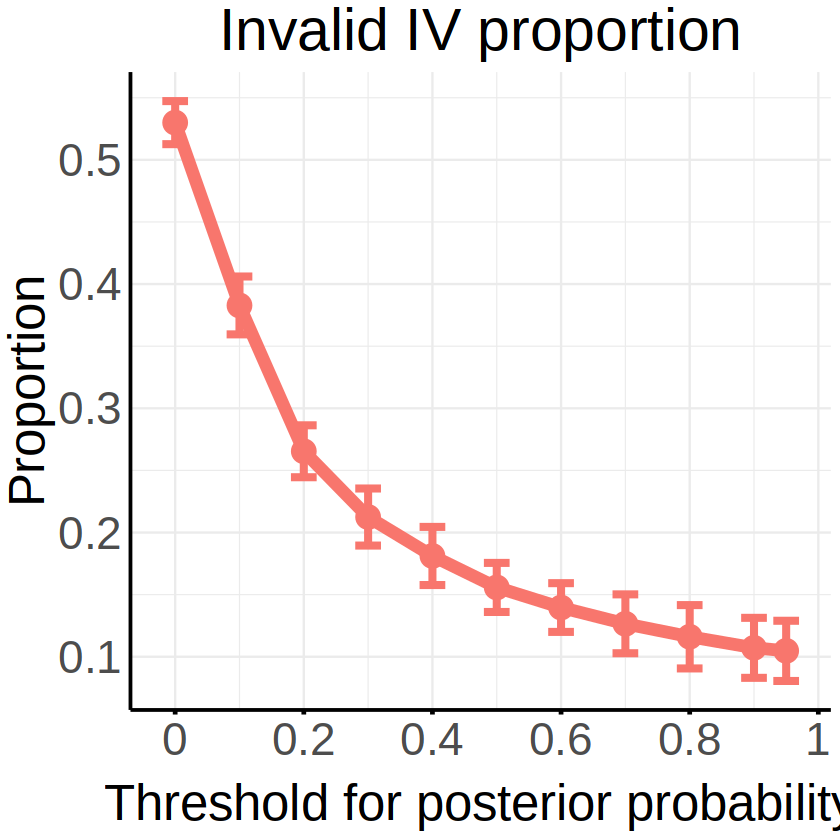

In [124]:
library(dplyr)

valid_thresh = c(0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0)
res_post3 = NULL

for(i in 1:30){
    
    trial = read.csv(paste0(base_dir, '/cor=',0.3,'_beta=',0,'_t=5e-05/IV_validity/experiment_', i, '.csv'))
    
    res_post_current = NULL
    
    for(j in 1:length(valid_thresh)){
        
        trial[dim(trial)[2]+1] = (trial$pi > valid_thresh[j])
        tab = table(trial$class, trial[, dim(trial)[2]])
        
        res_post_current = rbind(res_post_current, 
                                 data.frame(TPR_both=tab['both valid','TRUE']/sum(tab['both valid',]),
                                            FDR_both=(sum(tab[,'TRUE'])-tab['both valid','TRUE'])/sum(tab[,'TRUE']),
                                            FDR_tar=(tab['both invalid','TRUE']+tab['only aux valid','TRUE'])/sum(tab[,'TRUE']),
                                            filtered_invalid_prop = (sum(tab['both invalid',]) + sum(tab['only aux valid',]))/sum(tab),
                                            valid_threshold = valid_thresh[j]
                                            )
                            )
    }
    
    res_post3 = rbind(res_post3, res_post_current)

}

summary_data <- res_post3 %>%
  group_by(valid_threshold) %>%
  summarise(
    FDR_tar_mean = mean(FDR_tar, na.rm = TRUE),
    FDR_tar_sd = sd(FDR_tar, na.rm = TRUE),
    filtered_invalid_mean = mean(filtered_invalid_prop, na.rm = TRUE)
  )


ggplot(summary_data, aes(x = valid_threshold, y = FDR_tar_mean)) +
  geom_line(color = "#F8766D", size = 2.7) +
  geom_point(color = "#F8766D", size = 6.2) +
  geom_errorbar(aes(ymin = FDR_tar_mean - FDR_tar_sd, 
                    ymax = FDR_tar_mean + FDR_tar_sd), 
                size=1.7,width = 0.04, color = "#F8766D") +
  #geom_hline(yintercept = mean(summary_data$filtered_invalid_mean), 
  #           linetype = "dotdash", color = "red", size = 2) +
  labs(
    x = "Threshold for posterior probability",
    y = "Proportion",
    title = "Invalid IV proportion"
  ) +
  scale_x_continuous(
    breaks = c(0,0.2,0.4,0.6,0.8,1.0),
    labels = c(0,0.2,0.4,0.6,0.8,1.0)
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(size = 35, hjust = 0.5),
    axis.title.y = element_text(size = 30),
    axis.title.x = element_text(size = 30, hjust = 0.5, margin = margin(t = 12)),
    axis.text.x = element_text(size = 27),
    axis.text.y = element_text(hjust = 1, size = 27),
    axis.ticks.x = element_line(size = 1), 
    axis.line.x = element_line(size = 0.8, color = "black"),
    axis.line.y = element_line(size = 0.8, color = "black")
  )

ggsave(paste0(base_dir, '/plots/cor=0.3_FDR.png'), width = 9, height = 8, bg='white')